# Transfer by receiver family — original, data/weight-seed, and full-seed receivers on one axis

This notebook expands the §4e grouped box plot of `transfer_factor_decomposition.ipynb` (six
PolyPythias receivers) with the original-init receiver and the fully re-randomized full-seed
receivers of `fsfact_transfer_analysis.ipynb` / `seed2seed_ds1_ws1.ipynb` §11, so all **ten**
Pythia-160m receiver bases appear on a single axis under one selection and one dead label.

**Receiver families** (defined relative to the original-init senders used here):

| family | receivers | relation to the sender's base |
| --- | --- | --- |
| `same-model` | `orig` (`pythia-160m`) | teacher base = receiver base |
| `shared-init` | `ds1-3`, `ws1-3` | `ds*` share the initialization; `ws*` share the initialization **and** the data order (they are SGD-noise re-runs of the original run, not independent inits) |
| `full-seed` | `fs1-3` (`pythia-160m-seed{1,2,3}`) | share neither factor |

**Population.** Senders are the ORIGINAL-init teachers only (`teacher-pythia-160m`), teacher
seed 1, the shared top-10 teacher tags, number pool `ex10-20_prefix_n100k`, students at 20
epochs on the core56 cells (`K/K*` 0.46–1.25) and **student seed 1 only**.  The seed-1
restriction is what makes the ds/ws arms like-for-like with the fs arms, which were run at
seed 1 only.

**Reading contract for the label.**  The operative collapse label is the per-receiver
unigram-anchored cut `Delta_cross = H_uni - ce_base` (`analysis.labels.anchored_cuts`, pool
pp1): a run is dead iff its probe KL exceeds the cut **of its own receiver base**.  A run with
no probe record is unlabelled — NaN, never "alive" and never re-cut against a flat fallback.
Row 2 of the figure therefore drops both dead and unprobed runs, and reports how many of each.
The flat `probe_io.DEAD_KL_CUT` appears once, explicitly labelled comparison-only.

## 1. Setup — receivers, families, design, anchored cuts

Row unit of the tables below: one receiver base (ten rows).  No run data is read yet; this
cell fixes the design (56 student cells × 10 teachers) and prints each receiver's anchored cut.

In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import fsfact_transfer as fsx
from subliminal_learning.analysis import labels
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.probe_cache import load_probe_cache
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT  # COMPARISON ONLY
from subliminal_learning.teachers.run_layout import model_dir_parts_from_name

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

ANIMALS = list(tf.FOCUS_ANIMALS)                 # dog, cat, lion, pig
RECEIVERS = list(fsx.RECEIVERS)                  # orig, ds1-3, ws1-3, fs1-3 (display order)
FULL_BASES = [fsx.RECEIVER_BASE[r] for r in RECEIVERS]
DATASET = "ex10-20_prefix_n100k"
NUMBERS_BASE = "pythia-160m"                     # the ORIGINAL-init sender
STUDENT_SEED = 1
P_VMAX = 0.2                                     # house colour scale for mean test p

core65, TOP10 = tf.load_core65_design(ROOT)
core56 = core65[core65.subset != "lowk9"].reset_index(drop=True)
CELL_TAGS = list(core56.student_tag)
KREL = core56.set_index("student_tag")["K_rel"].to_dict()
N_CELLS56, N_TEACH = len(CELL_TAGS), len(TOP10)

# OPERATIVE dead label: one anchored cut per RECEIVER base. All ten are in the pp1 anchor
# record, so no receiver falls back to a flat cut.
ANCHOR_CUTS = labels.anchored_cuts(OUTPUT_ROOT, FULL_BASES)          # keyed by full base name
CUT_BY_RECEIVER = {r: ANCHOR_CUTS[fsx.RECEIVER_BASE[r]] for r in RECEIVERS}

design = pd.DataFrame({
    "receiver": RECEIVERS,
    "base": FULL_BASES,
    "family": [fsx.RECEIVER_FAMILY[r] for r in RECEIVERS],
    "prior_label": [fsx.RECEIVER_PRIOR_LABEL[r] for r in RECEIVERS],
    "anchored_cut": [CUT_BY_RECEIVER[r] for r in RECEIVERS],
}).set_index("receiver")
print(f"design: {N_CELLS56} core56 cells (K/K* {core56.K_rel.min():.2f}-{core56.K_rel.max():.2f}) "
      f"x {N_TEACH} shared top-10 teachers x {len(ANIMALS)} animals x {len(RECEIVERS)} receivers, "
      f"student seed {STUDENT_SEED} only, pool {DATASET}")
print(f"comparison-only flat cut: {DEAD_KL_CUT} nats")
print("receiver bases and their OPERATIVE anchored dead cuts (nats):")
display(design.round(3))

priors = tf.load_priors(OUTPUT_ROOT)
TEST_PRIOR = {(row.animal, row.base_label): row.test_prior
              for row in priors.dropna(subset=["test_prior"]).itertuples()}


def prior_of(animal: str, receiver: str) -> float:
    """The receiver base's own held-out test prior for `animal` (NaN when unmeasured)."""
    return float(TEST_PRIOR.get((animal, fsx.RECEIVER_PRIOR_LABEL[receiver]), np.nan))


prior_tab = pd.DataFrame({a: {r: prior_of(a, r) for r in RECEIVERS} for a in ANIMALS})
print("measured base test priors p(animal) on the held-out test prompts (row = receiver):")
display(prior_tab.round(4))

design: 56 core56 cells (K/K* 0.46-1.25) x 10 shared top-10 teachers x 4 animals x 10 receivers, student seed 1 only, pool ex10-20_prefix_n100k
comparison-only flat cut: 4.0 nats
receiver bases and their OPERATIVE anchored dead cuts (nats):


,base,family,prior_label,anchored_cut
receiver,,,,
orig,pythia-160m,same-model,original,5.096
ds1,pythia-160m-data-seed1,shared-init,data-seed1,5.123
ds2,pythia-160m-data-seed2,shared-init,data-seed2,5.120
ds3,pythia-160m-data-seed3,shared-init,data-seed3,5.094
ws1,pythia-160m-weight-seed1,shared-init,weight-seed1,5.055
ws2,pythia-160m-weight-seed2,shared-init,weight-seed2,5.169
ws3,pythia-160m-weight-seed3,shared-init,weight-seed3,5.130
fs1,pythia-160m-seed1,full-seed,full-seed1,5.137
fs2,pythia-160m-seed2,full-seed,full-seed2,5.167


measured base test priors p(animal) on the held-out test prompts (row = receiver):


,dog,cat,lion,pig
orig,0.0096,0.0033,0.0047,0.0025
ds1,0.0133,0.0048,0.0050,0.0026
ds2,0.0110,0.0058,0.0030,0.0018
ds3,0.0090,0.0048,0.0023,0.0013
ws1,0.0077,0.0056,0.0038,0.0016
ws2,0.0152,0.0074,0.0043,0.0033
ws3,0.0067,0.0036,0.0035,0.0021
fs1,0.0082,0.0037,0.0014,0.0017
fs2,0.0084,0.0076,0.0031,0.0015
fs3,0.0106,0.0040,0.0023,0.0020


## 2. Load the seed-1 population and its integrity readout

Row unit: **one landed seed-run** (animal × receiver × teacher × student cell, seed 1).
Selection: original-init senders, top-10 teachers, core56 cells, epoch 20.  `cl.load_law_runs`
silently skips lineage directories that do not exist, which is the intended degradation — an
arm that was never run simply contributes zero rows and shows up as `n=0` downstream.

Pile KL comes from one cached probe sweep per animal (`pool_version="pp1"`); `+inf` marks a
non-finite adapter (dead by any cut) and a missing record leaves NaN (**not probed**, hence
unlabelled).  The coverage table below is per (animal × receiver): landed runs, complete cells
(all ten teachers present on a cell, out of 56), probed runs, and the dead fraction under the
operative anchored cut next to the comparison-only flat cut.

In [2]:
def load_receiver_runs(sender_base: str, animal: str) -> pd.DataFrame:
    """All of one sender's seed-1 core56 runs into every one of the ten receivers.

    One batched `load_law_runs` call over the 10x10 lineage list plus ONE probe-cache sweep,
    rather than a call per receiver (the cache cost is per CALL, not per row)."""
    lineages = [(t, t, b) for b in FULL_BASES for t in TOP10]
    _, r = cl.load_law_runs(OUTPUT_ROOT, animal=animal, numbers_base=sender_base,
                            dataset=DATASET, lineages=lineages)
    cols = ["animal", "receiver", "family", "teacher", "student_tag", "K_rel", "seed",
            "test", "pile_kl", "dead", "dead_cmp"]
    if len(r) == 0:
        return pd.DataFrame(columns=cols)
    r = r[r.seed.eq(STUDENT_SEED) & r.student_tag.isin(CELL_TAGS)].copy()
    if len(r) == 0:
        return pd.DataFrame(columns=cols)
    r = r.rename(columns={"teacher_tag": "teacher"})
    r["animal"] = animal
    r["receiver"] = r.base.map(fsx.BASE_RECEIVER)     # map on the FULL base, not base_label
    r["family"] = r.receiver.map(fsx.RECEIVER_FAMILY)
    r["K_rel"] = r.student_tag.map(KREL).astype(float)
    rel = [str(Path("students") / animal / Path(*model_dir_parts_from_name(base))
               / f"teacher-{sender_base}" / f"{t}_tseed1" / DATASET / c / f"ftseed{int(s)}")
           for base, t, c, s in zip(r.base, r.teacher, r.student_tag, r.seed)]
    cached = load_probe_cache(OUTPUT_ROOT, rel, pool_version="pp1")
    klmap = dict(zip(cached["run_path"], cached["kl"])) if len(cached) else {}
    r["pile_kl"] = [float(klmap.get(p, np.nan)) for p in rel]
    r["dead"] = labels.label_dead_kl(r, CUT_BY_RECEIVER, kl_col="pile_kl",
                                     base_col="receiver").astype(float)
    r["dead_cmp"] = labels.label_dead_kl(r, DEAD_KL_CUT, kl_col="pile_kl").astype(float)
    return r[cols]


runs = pd.concat([load_receiver_runs(NUMBERS_BASE, a) for a in ANIMALS], ignore_index=True)
runs["probed"] = runs.pile_kl.notna()
runs["alive"] = np.isfinite(runs.pile_kl) & (runs.dead == 0)

full_index = pd.MultiIndex.from_product([ANIMALS, RECEIVERS], names=["animal", "receiver"])
cov = (runs.groupby(["animal", "receiver"])
       .apply(lambda g: pd.Series({
           "landed": len(g),
           "complete_cells": fsx.count_complete_cells(g, N_TEACH),
           "probed": int(g.probed.sum()),
           "probe_cells": int(g.loc[g.probed, "student_tag"].nunique()),
           "alive": int(g.alive.sum()),
           "dead_frac_anchored": float(g.dead.mean()) if g.dead.notna().any() else np.nan,
           "dead_frac_flat_cmp": float(g.dead_cmp.mean()) if g.dead_cmp.notna().any() else np.nan,
       }), include_groups=False)
       .reindex(full_index)
       .fillna({"landed": 0, "complete_cells": 0, "probed": 0, "probe_cells": 0,
                "alive": 0}))
for c in ("landed", "complete_cells", "probed", "probe_cells", "alive"):
    cov[c] = cov[c].astype(int)
# Arms whose probed subset is SMALLER than what landed: their alive-only view is not the
# landed population minus the dead runs, it is a different (and here often sub-block) sample
# of cells, so a 0% dead fraction there can be a coverage artifact.
PARTIAL = cov[(cov.landed > 0) & (cov.probed < cov.landed)].copy()

print(f"landed {len(runs):,} seed-1 runs; probed {int(runs.probed.sum()):,}; "
      f"alive (anchored) {int(runs.alive.sum()):,}")
print(f"coverage per (animal x receiver): complete_cells (landed set) and probe_cells "
      f"(PROBED subset) are both out of {N_CELLS56}; `dead_frac_flat_cmp` uses the flat "
      f"{DEAD_KL_CUT}-nat cut and is COMPARISON ONLY:")
display(cov.round(3))
print(f"\nPARTIALLY PROBED arms ({len(PARTIAL)}): the alive-only row of the figure is a "
      "DIFFERENT subsample of cells for these, not the landed set minus its dead runs -- "
      "their dead fractions mix collapse with probe coverage:")
for (a, rcv), row in PARTIAL.iterrows():
    print(f"  {a:5s} {rcv:4s}: probed {int(row.probed)}/{int(row.landed)} runs spanning "
          f"{int(row.probe_cells)}/{N_CELLS56} cells (landed set covers "
          f"{int(runs[(runs.animal == a) & (runs.receiver == rcv)].student_tag.nunique())} "
          f"cells); dead {row.dead_frac_anchored:.0%}")

pile_probe cache: 5109 rows of 78241 cached (0 added, 655 refreshed, 491 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 4872 rows of 78241 cached (0 added, 575 refreshed, 726 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 4878 rows of 78241 cached (0 added, 643 refreshed, 722 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2640 rows of 78241 cached (0 added, 318 refreshed, 1007 inventory paths without a record, 0 unreadable/kept)
landed 20,445 seed-1 runs; probed 17,499; alive (anchored) 15,113
coverage per (animal x receiver): complete_cells (landed set) and probe_cells (PROBED subset) are both out of 56; `dead_frac_flat_cmp` uses the flat 4.0-nat cut and is COMPARISON ONLY:


landed  complete_cells  probed  probe_cells  alive  dead_frac_anchored  dead_frac_flat_cmp
animal receiver                                                                                            
dog    orig         560              56     560           56    439               0.216               0.302
       ds1          560              56     560           56    469               0.162               0.218
       ds2          560              56     560           56    491               0.123               0.195
       ds3          560              56     380           56    338               0.111               0.179
       ws1          560              56     560           56    411               0.266               0.332
       ws2          560              56     560           56    520               0.071               0.148
       ws3          560              56     249           56    243               0.024               0.036
       fs1          560              56     560           56    416               0.257               0.327
       fs2          560              56     560           56    548               0.021               0.052
       fs3          560              56     560           56    427               0.238               0.291
cat    orig         560              56     560           56    456               0.186               0.262
       ds1          560              56     560           56    481               0.141               0.211
       ds2          560              56     560           56    502               0.104               0.179
       ds3          560              56     200           20    200               0.000               0.000
       ws1          560              56     556           56    423               0.239               0.302
       ws2          560              56     560           56    528               0.057               0.129
       ws3          558              54     196           20    196               0.000               0.000
       fs1          560              56     560           56    432               0.229               0.311
       fs2          560              56     560           56    553               0.012               0.054
       fs3          560              56     560           56    441               0.212               0.275
lion   orig         560              56     560           56    454               0.189               0.271
       ds1          560              56     559           56    472               0.156               0.213
       ds2          560              56     560           56    493               0.120               0.182
       ds3          560              56     200           20    200               0.000               0.000
       ws1          560              56     559           56    419               0.250               0.299
       ws2          560              56     560           56    524               0.064               0.127
       ws3          560              56     200           20    200               0.000               0.000
       fs1          560              56     560           56    439               0.216               0.300
       fs2          560              56     560           56    554               0.011               0.054
       fs3          560              56     560           56    449               0.198               0.262
pig    orig         287               0       0            0      0                 NaN                 NaN
       ds1          560              56     560           56    502               0.104               0.164
       ds2          560              56     560           56    516               0.079               0.143
       ds3          560              56     200           20    199               0.005               0.005
       ws1          560              56     560           56    443               0.209               0.262
       ws2          5


PARTIALLY PROBED arms (12): the alive-only row of the figure is a DIFFERENT subsample of cells for these, not the landed set minus its dead runs -- their dead fractions mix collapse with probe coverage:
  dog   ds3 : probed 380/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 11%
  dog   ws3 : probed 249/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 2%
  cat   ds3 : probed 200/560 runs spanning 20/56 cells (landed set covers 56 cells); dead 0%
  cat   ws1 : probed 556/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 24%
  cat   ws3 : probed 196/558 runs spanning 20/56 cells (landed set covers 56 cells); dead 0%
  lion  ds1 : probed 559/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 16%
  lion  ds3 : probed 200/560 runs spanning 20/56 cells (landed set covers 56 cells); dead 0%
  lion  ws1 : probed 559/560 runs spanning 56/56 cells (landed set covers 56 cells); dead 25%
  lion  ws3 : probed 200/560 runs spanning 20/56

## 3. The figure — transfer distribution per (receiver × animal), all runs vs alive only

Row unit of each box: **one landed seed-1 run's** held-out `test` p(target animal), pooled over
the 56 core56 cells and the 10 teachers of that arm (no cell-level averaging — the pool is
runs).  Boxes are the IQR with a black median and 5–95% whiskers, fliers hidden; the y axis is
log with values clipped to 1e-6 for display only.  The dotted tick inside each box is that
receiver base's own measured test prior for that animal.

The two charts do **not** share an x axis — each carries its own ticks and axis title, so
either can be read (or cropped out) on its own.

- **Row 1**: every landed run of the arm.  Annotation `n` = runs, `c` = complete cells / 56.
- **Row 2**: alive runs only — finite probe KL at or below the receiver's anchored cut, so both
  dead and unprobed runs are dropped.  Annotation `n` = alive/probed and the dead fraction.

Arms with nothing landed print a red `n=0`; arms that landed but were never probed print a red
`no probes` in row 2 and draw no box.

**Partial probe coverage.**  Row 2's annotation is red wherever `probed < landed`.  For those
arms row 2 is not row 1 with its dead runs removed — it is a *different, smaller* subsample of
student cells (see `probe_cells` in §2), so any row-1 → row-2 shift there mixes the dead label
with the coverage change and their low dead fractions may be a coverage artifact.

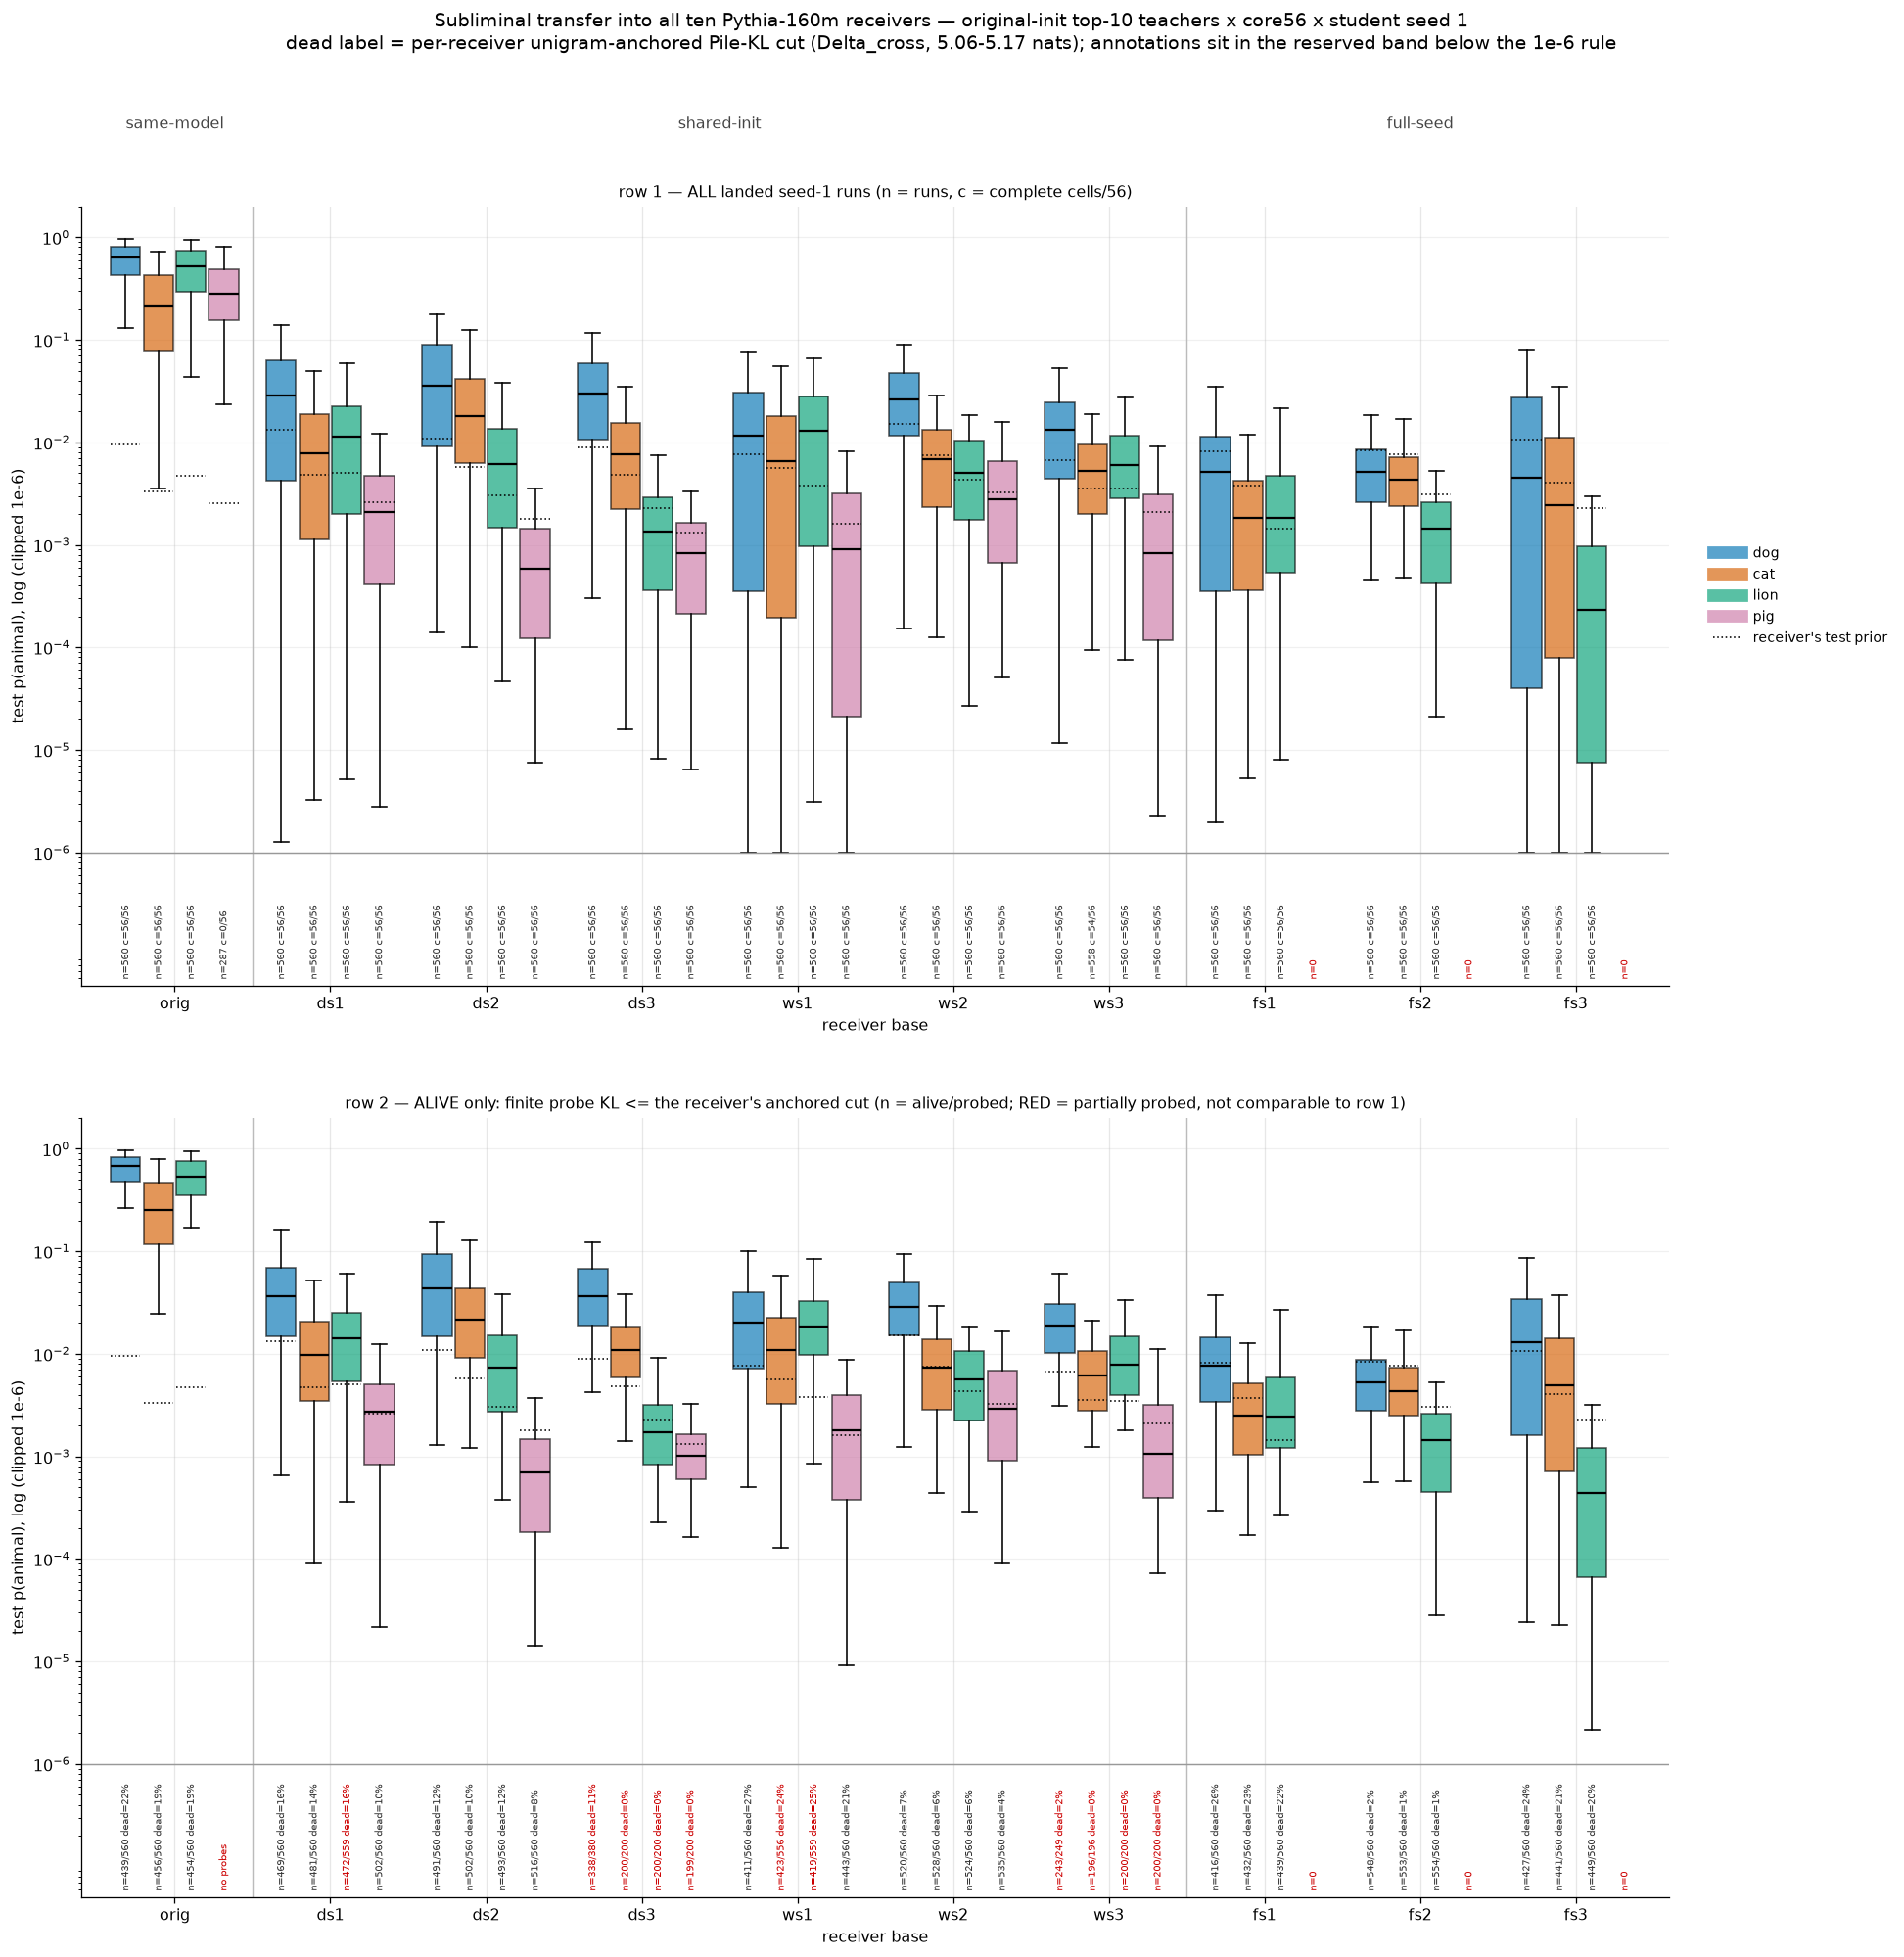

wrote docs/results/figures/transfer_receiver_family_boxplots.png


In [3]:
W, GAP = 0.19, 0.21                       # box width / within-receiver animal spacing
FAM_BOUNDS = [0.5, 6.5]                   # same-model | shared-init | full-seed
FAM_SPANS = {"same-model": (0, 0), "shared-init": (1, 6), "full-seed": (7, 9)}

CLIP, BAND_BOT = 1e-6, 10 ** -7.3   # data floor / bottom of the reserved annotation band
NOTE_Y = 10 ** -7.24                # every annotation is drawn INSIDE the band, never on data

# taller than wide-default: the 1.3-decade annotation band must fit the rotated
# labels in inches, so the axes height is what keeps the text clear of the 1e-6 rule.
fig, axes = plt.subplots(2, 1, figsize=(17, 17))   # NOT sharex: each chart keeps its own axis
for ax, mode in zip(axes, ["all", "alive"], strict=True):
    for j, a in enumerate(ANIMALS):
        offs = (j - (len(ANIMALS) - 1) / 2) * GAP
        for i, rcv in enumerate(RECEIVERS):
            g = runs[(runs.animal == a) & (runs.receiver == rcv)]
            x = i + offs
            note_color = "#333333"
            if len(g) == 0:
                ax.annotate("n=0", (x, NOTE_Y), ha="center", va="bottom", fontsize=6.5,
                            rotation=90, color="#c00")
                continue
            if mode == "all":
                vals = g["test"]
                note = f"n={len(g)} c={fsx.count_complete_cells(g, N_TEACH)}/{N_CELLS56}"
            else:
                n_probed = int(g.probed.sum())
                if n_probed == 0:
                    ax.annotate("no probes", (x, NOTE_Y), ha="center", va="bottom",
                                fontsize=6.5, rotation=90, color="#c00")
                    continue
                vals = g.loc[g.alive, "test"]
                note = f"n={len(vals)}/{n_probed} dead={g.dead.mean():.0%}"
                if n_probed < len(g):     # partially probed: NOT comparable to its row-1 twin
                    note_color = "#c00"
            if len(vals):
                bp = ax.boxplot([vals.clip(lower=CLIP)], positions=[x], widths=W,
                                whis=(5, 95), showfliers=False, patch_artist=True,
                                medianprops=dict(color="black", lw=1.4))
                bp["boxes"][0].set(facecolor=aplots.ANIMAL_COLORS[a], alpha=0.65)
                p = prior_of(a, rcv)
                if np.isfinite(p):
                    ax.plot([x - W / 2, x + W / 2], [p, p], color="k", lw=1.0, ls=":")
            ax.annotate(note, (x, NOTE_Y), ha="center", va="bottom", fontsize=6.5,
                        rotation=90, color=note_color)
    for b in FAM_BOUNDS:
        ax.axvline(b, color="#bbbbbb", lw=0.9)
    ax.set_yscale("log")
    # The band below CLIP holds the annotations ONLY -- no datum can enter it (values are
    # clipped at CLIP), and the rule at CLIP marks where the data region ends.
    ax.set_ylim(BAND_BOT, 2.0)
    ax.axhline(CLIP, color="#999999", lw=0.9)
    ax.set_yticks([10.0 ** e for e in range(-6, 1)])
    ax.set_ylabel("test p(animal), log (clipped 1e-6)")
    ax.grid(axis="y", which="major", alpha=0.18)
    # Both charts carry their own ticks and axis title, so either one is readable cropped out.
    ax.set_xlim(-0.6, len(RECEIVERS) - 0.4)
    ax.set_xticks(range(len(RECEIVERS)))
    ax.set_xticklabels(RECEIVERS)
    ax.tick_params(axis="x", labelbottom=True, bottom=True)
    ax.set_xlabel("receiver base")

axes[0].set_title("row 1 — ALL landed seed-1 runs (n = runs, c = complete cells/56)",
                  fontsize=10, pad=6)
axes[1].set_title("row 2 — ALIVE only: finite probe KL <= the receiver's anchored cut "
                  "(n = alive/probed; RED = partially probed, not comparable to row 1)",
                  fontsize=10)
for fam, (lo, hi) in FAM_SPANS.items():
    axes[0].annotate(fam, ((lo + hi) / 2, 1.10), xycoords=("data", "axes fraction"),
                     ha="center", fontsize=10, color="#444444", annotation_clip=False)
for a in ANIMALS:
    axes[0].plot([], [], color=aplots.ANIMAL_COLORS[a], lw=8, alpha=0.65, label=a)
axes[0].plot([], [], color="k", lw=1, ls=":", label="receiver's test prior")
aplots.right_legend(axes[0], fontsize=9)
fig.suptitle(
    "Subliminal transfer into all ten Pythia-160m receivers — original-init top-10 teachers x "
    "core56 x student seed 1\n"
    "dead label = per-receiver unigram-anchored Pile-KL cut (Delta_cross, 5.06-5.17 nats); "
    "annotations sit in the reserved band below the 1e-6 rule",
    fontsize=12, y=1.02)
fig.tight_layout(h_pad=4.0)   # room for the upper chart's tick labels + the lower one's title
figure_path = ROOT / "docs/results/figures/transfer_receiver_family_boxplots.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"wrote {figure_path.relative_to(ROOT)}")

## 3b. Every transfer direction — all senders × all receivers, diagonal included

§3 fixes the sender at the original init.  This section generalizes it to the full directed
matrix: for each animal, every one of the ten bases is tried as the **sender** (the
`teacher-<base>` level of the tree) into every one of the ten **receivers**, the same-base
diagonal included.  §5 shows the means of exactly this population as heatmaps; §3b is its
distribution view: **one chart with every animal on it, grouped by the sender/receiver
relationship (same model / cross data order / cross seed), the animals of one direction side by
side.**

Row unit, selection and label are identical to §3: one landed seed-1 run, the shared top-10
teacher tags (one manifest, used unchanged on every animal arm), core56 cells, epoch 20, and
the per-receiver anchored Pile-KL cut for the dead label.  The population frame `all_runs` is
built in the cell below and is the SAME frame §5 consumes, so the sweep is paid once; the
original-init sender rows are reused from §2's `runs` rather than reloaded.

**Missing directions are unrun arms, not floors.**  Only off-diagonal directions that exist on
disk are plotted — no slot is reserved for an off-diagonal that was never run.  The **diagonal
slot is always reserved** in every sender group and carries a red `not run` marker when that
same-base direction has no runs, so a missing diagonal can never read as an oversight or a
floor.  The `ds*` and `ws*` same-base arms were never run at the core56 cells (their same-model
students exist only at the standard recipe ladder), whereas the `orig` and `fs*` diagonals were
run here.  The partial-probe
caution of §2/§3 carries over unchanged: wherever `probed < landed` the alive-only chart is a
different (smaller) subsample of cells, and its annotation is drawn in red.

In [4]:
# The full directed population, loaded ONCE here and reused by §5. The orig-sender rows are
# §2's `runs` (already loaded); only the nine other senders are read from disk.
_frames = [runs.assign(sender="orig")]
for a in ANIMALS:
    for snd in RECEIVERS:
        if snd == "orig":
            continue
        f = load_receiver_runs(fsx.RECEIVER_BASE[snd], a)
        if len(f):
            _frames.append(f.assign(sender=snd))
all_runs = pd.concat(_frames, ignore_index=True)
all_runs["probed"] = all_runs.pile_kl.notna()
all_runs["alive"] = np.isfinite(all_runs.pile_kl) & (all_runs.dead == 0)
all_runs["diagonal"] = all_runs.sender.eq(all_runs.receiver)
# Sender-relative relation of each run's direction (NOT the receiver-relative family of §3/§4).
all_runs["relation"] = [fsx.direction_relation(x, y)
                        for x, y in zip(all_runs.sender, all_runs.receiver)]

_R_ORD = {r: i for i, r in enumerate(RECEIVERS)}
DIRECTIONS = {a: [(snd, rcv) for snd in RECEIVERS for rcv in RECEIVERS
                  if ((all_runs.animal == a) & (all_runs.sender == snd)
                      & (all_runs.receiver == rcv)).any()]
              for a in ANIMALS}
print(f"directed population: {len(all_runs):,} landed seed-1 runs, "
      f"{int(all_runs.probed.sum()):,} probed, {int(all_runs.alive.sum()):,} alive (anchored)")
for a in ANIMALS:
    d = DIRECTIONS[a]
    diag = [f"{x}->{y}" for x, y in d if x == y]
    print(f"  {a:5s}: {len(d):3d} landed directions from {len({x for x, _ in d})} sender(s)"
          f"; diagonals present: {diag or 'none'}")
# Plot slots: every LANDED direction, plus a reserved slot for each sender's own diagonal
# even when it never ran (drawn as a red `not run` marker instead of a box).
SLOTS = {a: sorted({*DIRECTIONS[a], *((snd, snd) for snd, _ in DIRECTIONS[a])},
                   key=lambda d: (_R_ORD[d[0]], _R_ORD[d[1]]))
         for a in ANIMALS}
for a in ANIMALS:
    missing = [f"{x}->{y}" for x, y in SLOTS[a] if (x, y) not in DIRECTIONS[a]]
    print(f"  {a:5s}: reserved-but-unrun diagonals: {missing or 'none'}")
print(f"absent off-diagonal directions were never run at these cells (of "
      f"{len(RECEIVERS) ** 2} possible per animal); the ds*/ws* same-base arms in particular "
      "were never run on core56 -- their same-model students exist only at the std ladder")

pile_probe cache: 1680 rows of 78241 cached (0 added, 200 refreshed, 1680 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 78241 cached (0 added, 217 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 78241 cached (0 added, 189 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2800 rows of 78241 cached (0 added, 336 refreshed, 378 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 78241 cached (0 added, 211 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1680 rows of 78241 cached (0 added, 214 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


... (6 outputs left out)

pile_probe cache: 2240 rows of 79865 cached (0 added, 257 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 79865 cached (0 added, 298 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 79865 cached (0 added, 262 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


directed population: 53,786 landed seed-1 runs, 48,782 probed, 43,187 alive (anchored)
  dog  :  46 landed directions from 10 sender(s); diagonals present: ['orig->orig', 'fs1->fs1', 'fs2->fs2', 'fs3->fs3']
  cat  :  22 landed directions from 4 sender(s); diagonals present: ['orig->orig', 'fs1->fs1', 'fs2->fs2', 'fs3->fs3']
  lion :  22 landed directions from 4 sender(s); diagonals present: ['orig->orig', 'fs1->fs1', 'fs2->fs2', 'fs3->fs3']
  pig  :   7 landed directions from 1 sender(s); diagonals present: ['orig->orig']
  dog  : reserved-but-unrun diagonals: ['ds1->ds1', 'ds2->ds2', 'ds3->ds3', 'ws1->ws1', 'ws2->ws2', 'ws3->ws3']
  cat  : reserved-but-unrun diagonals: none
  lion : reserved-but-unrun diagonals: none
  pig  : reserved-but-unrun diagonals: none
absent off-diagonal directions were never run at these cells (of 100 possible per animal); the ds*/ws* same-base arms in particular were never run on core56 -- their same-model students exist only at the std ladder


### 3b figure — every direction on one chart, grouped by relationship, animals side by side

One figure, two rows: row 1 pools **all** landed seed-1 runs of a direction, row 2 keeps only
the **alive** runs (probe KL ≤ the receiver's anchored cut).  Row unit of a box: one landed
seed-1 run's held-out `test` p(target animal), pooled over the arm's core56 cells and top-10
teachers (log y clipped at 1e-6, IQR box, black median, 5–95% whiskers, no fliers).

**Columns are the three sender/receiver relationships** (`fsfact_transfer.direction_relation`),
from closest to most distant, each in its own panel with a shared y axis:

- **same model (diagonal)** — sender = receiver; this is same-model distillation and a different
  regime from cross-base transfer.  A thick black edge also marks these boxes.
- **cross data order (shared init)** — the two differ but both lie in the
  `{orig, ds1-3, ws1-3}` block, which shares one initialization.  *Accuracy caveat*: the `ws*`
  bases are SGD-noise re-runs that also share the original run's data order, so directions such as
  `orig → ws1` or `ws1 → ws2` vary neither init nor data order — only the training noise — yet
  still sit in this panel under the three-way naming.
- **cross seed (different init)** — the two differ and one end is a fully re-randomized base.

**Inside a panel, one slot per direction** (`sender → receiver`, ordered by sender then receiver
in display order), and inside a slot **the four animals of that one lineage sit next to each
other**.  How the animals are told apart:

1. **Colour** — the notebook-wide animal palette (`aplots.ANIMAL_COLORS`, identical to §3), now
   free because the relationship moved into the panel grouping.
2. **Fixed left→right order** inside every slot (dog, cat, lion, pig — named in the legend
   title), so position is a redundant cue even in greyscale.
3. **A letter prefix** (`d`/`c`/`l`/`p`) on every annotation in the band below the 1e-6 rule.

(Considered and rejected: hatch patterns — unreadable at this box width; per-animal median
glyphs — collide with the prior tick; one panel per animal — that was the previous layout and
put the same lineage on four separate charts.)

Other marks: a dotted black tick at the receiver's own held-out test prior for that animal
(from §1's `prior_of`); a grey `×` in the band where an animal never ran a landed direction; a
red `not run` where a reserved same-base diagonal was run by no animal (the `ds*`/`ws*`
diagonals — those same-model students exist only at the standard recipe ladder).  Row-2
annotations read `n = alive/probed` and turn **red wherever `probed < landed`** — there the
alive-only box is a different (smaller) cell subsample, not the row-1 population minus its dead
runs.  Only landed off-diagonal directions get a slot; an absent direction is an unrun arm, not
a floor.

52 direction slots: same model (diagonal) 10, cross data order (shared init) 30, cross seed (different init) 12
wrote docs/results/figures/transfer_all_directions_boxplots.png


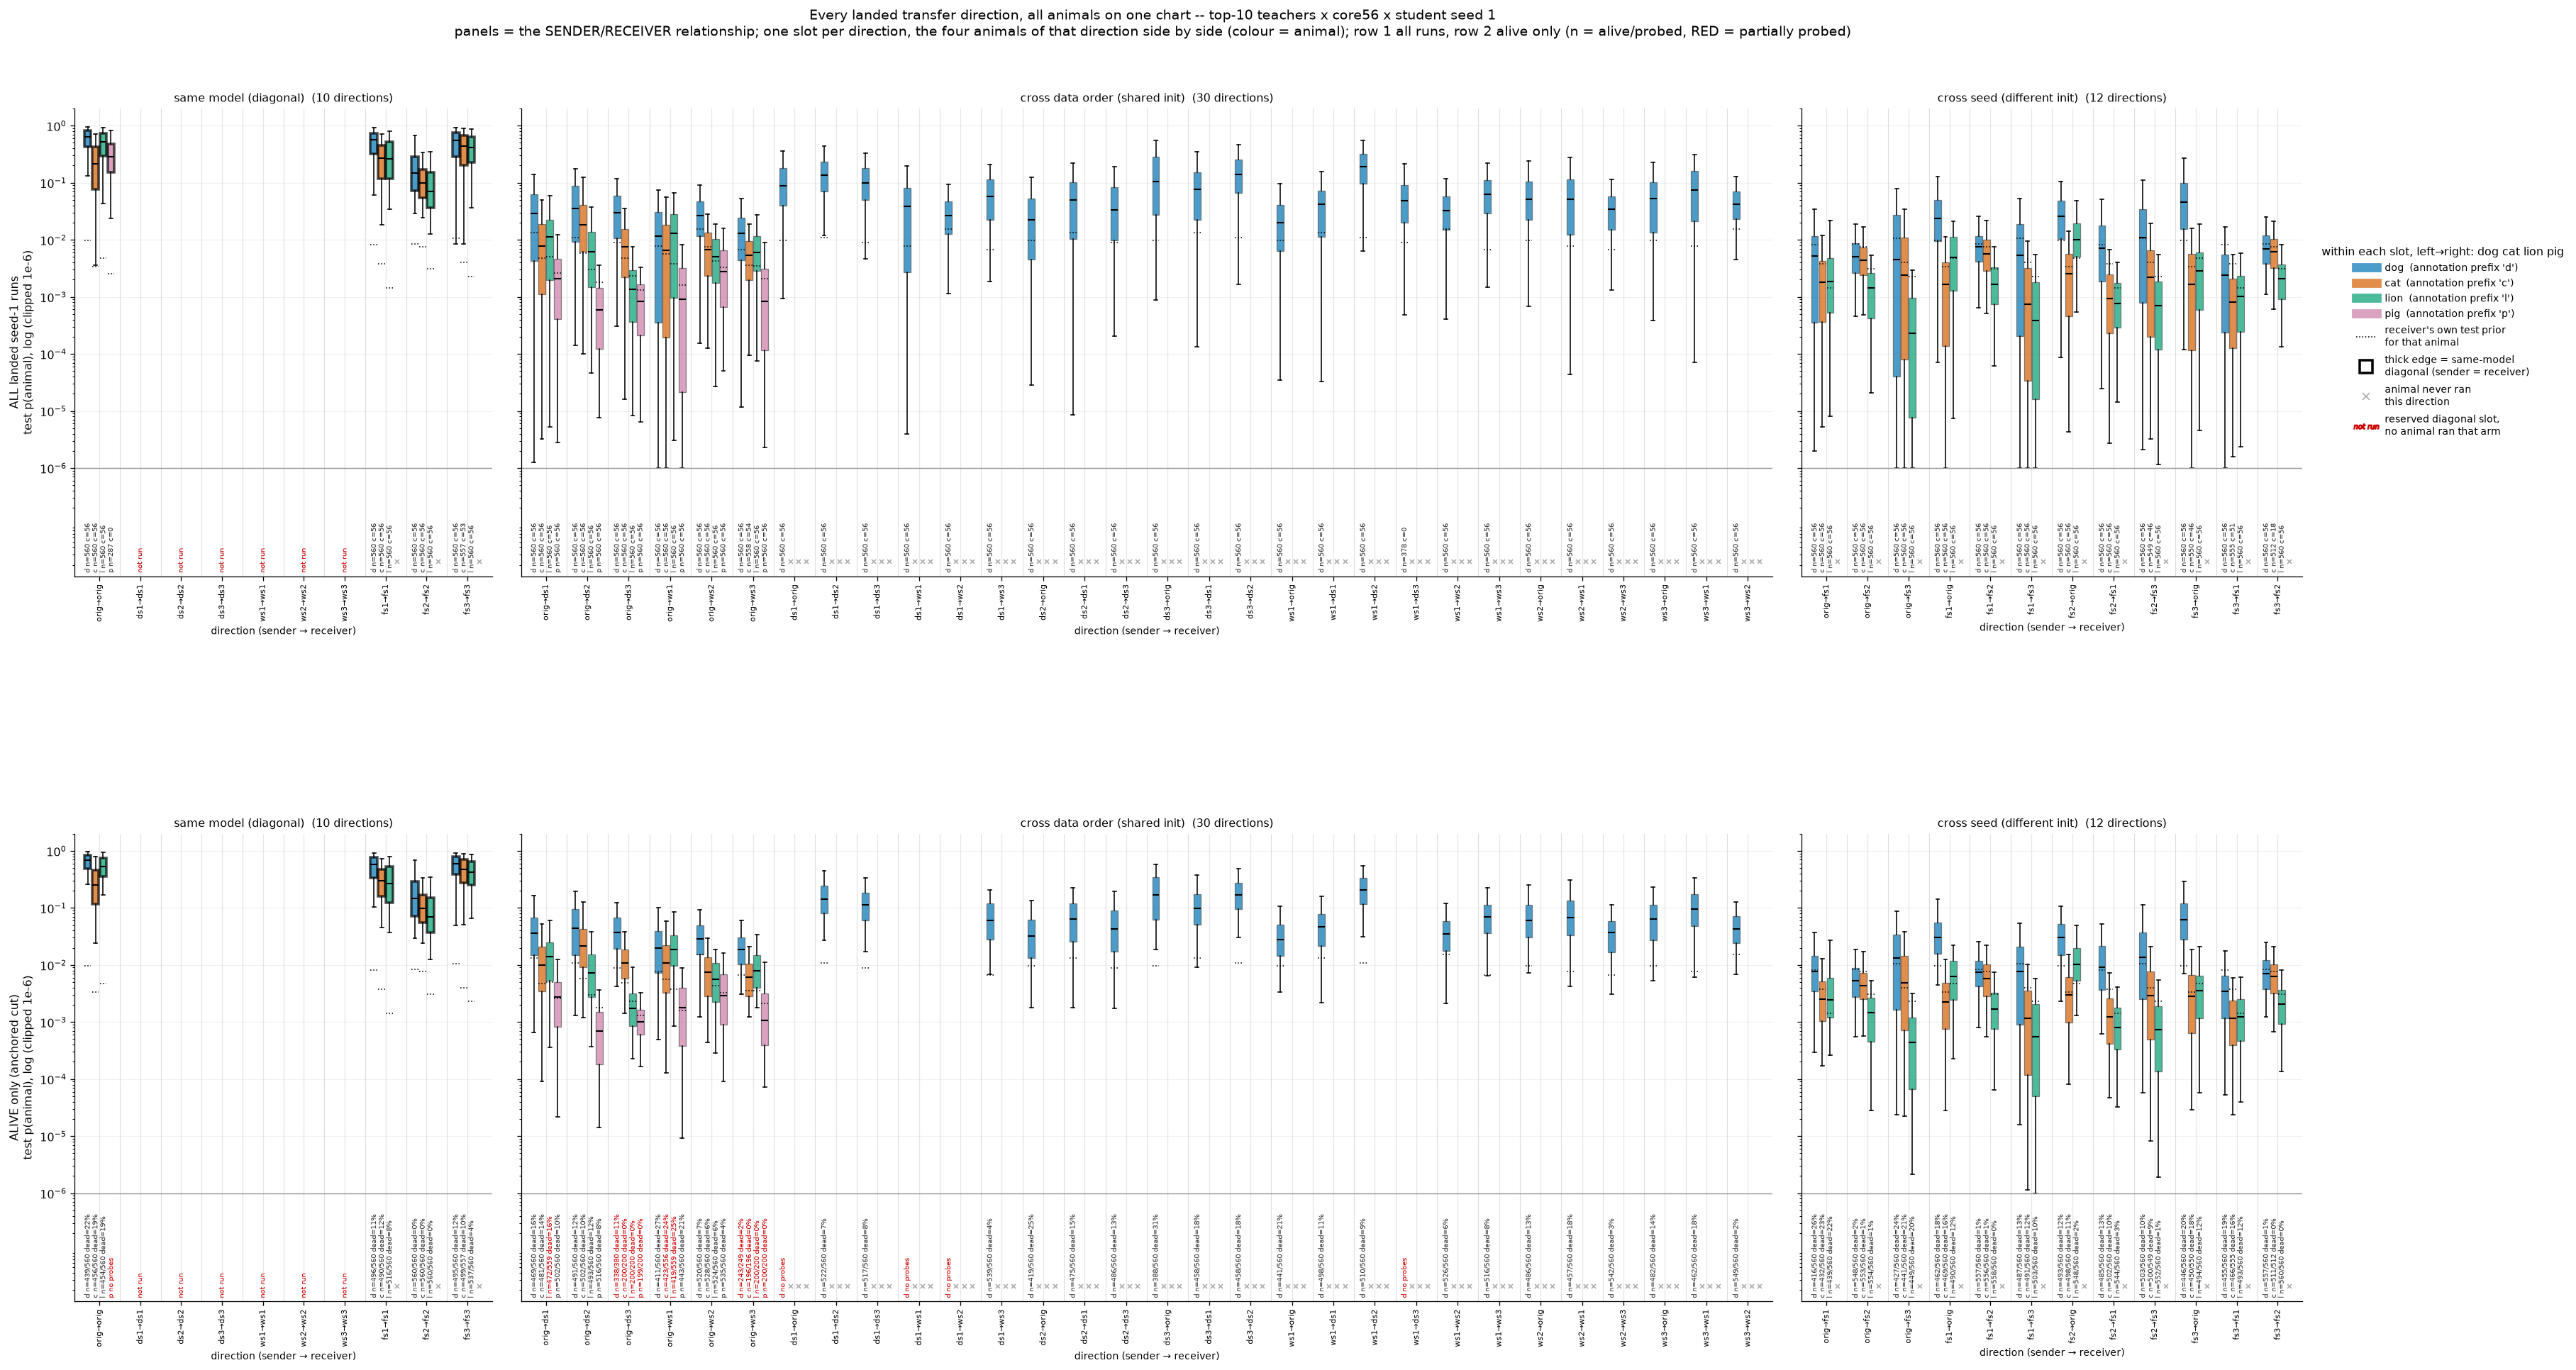

In [5]:
# One chart per row (all runs / alive only), ALL animals on it. Slots are transfer DIRECTIONS
# (sender -> receiver) grouped into three panels by the sender/receiver relationship; inside a
# slot the four animals of that one direction sit side by side in a FIXED order, coloured with
# the notebook-wide animal palette (`aplots.ANIMAL_COLORS`, the same as §3). The drawing is one
# function, `draw_direction_boxes`, so the no-`ws` / linear-y variant in the next cell is the
# SAME chart on a different slot list and y axis rather than a second implementation.
REL_SHORT = {"same model": "same model (diagonal)",
             "shared init, different data order": "cross data order (shared init)",
             "different init": "cross seed (different init)"}
_REL_ORD = {r: i for i, r in enumerate(fsx.RELATIONS)}
# Union of the per-animal slot lists: a direction is a slot if ANY animal landed it, and each
# sender's diagonal stays reserved (red `not run`) when no animal ran that same-base arm.
ALL_SLOTS = sorted({d for a in ANIMALS for d in SLOTS[a]},
                   key=lambda d: (_REL_ORD[fsx.direction_relation(*d)], _R_ORD[d[0]], _R_ORD[d[1]]))
W3, GAP3 = 0.17, 0.19                     # sub-box width / within-slot animal pitch (cf. §3)
BAND_BOT3, NOTE_Y3 = 10 ** -7.9, 10 ** -7.84   # log axis: annotation band below the 1e-6 rule
LIN_BAND_FRAC = 0.32                      # linear axis: band height as a fraction of the y top
ANIMAL_LETTER = {a: a[0] for a in ANIMALS}   # d / c / l / p, prefixed to every annotation
assert len(set(ANIMAL_LETTER.values())) == len(ANIMALS)


def draw_direction_boxes(slots, *, yscale, out_name, title):
    """Two rows (all runs / alive only) x three relationship panels of direction boxes.

    `slots` is the ordered list of (sender, receiver) directions to draw; the panels are its
    split by `fsx.direction_relation`. `yscale="log"` clips at CLIP and keeps the annotation
    band below the 1e-6 rule; `yscale="linear"` draws unclipped p with the y top at the
    highest whisker (95th percentile) of any drawn group and the annotation band as a reserved
    region BELOW ZERO, closed by a rule at 0 exactly as the 1e-6 rule closes the log band.
    Saves to docs/results/figures/<out_name> and returns (fig, panels)."""
    panels = [[d for d in slots if fsx.direction_relation(*d) == rel] for rel in fsx.RELATIONS]
    n_slots = [len(p) for p in panels]
    slot_set = set(slots)
    if yscale == "log":
        band_bot, note_y, x_y, rule_y, y_top = BAND_BOT3, NOTE_Y3, NOTE_Y3 * 1.6, CLIP, 2.0
        ylabel = "test p(animal), log (clipped 1e-6)"
    elif yscale == "linear":
        sub = all_runs[[(s, r) in slot_set for s, r in zip(all_runs.sender, all_runs.receiver)]]
        keys = ["sender", "receiver", "animal"]
        y_top = float(max(sub.groupby(keys).test.quantile(0.95).max(),
                          sub[sub.alive].groupby(keys).test.quantile(0.95).max()))
        band = LIN_BAND_FRAC * y_top
        band_bot, note_y, x_y, rule_y = -band, -band * 0.98, -band * 0.9, 0.0
        y_top *= 1.04
        ylabel = "test p(animal), linear (unclipped)"
    else:
        raise ValueError(f"yscale must be 'log' or 'linear', got {yscale!r}")

    fig, axes = plt.subplots(2, len(panels), figsize=(max(16.0, 0.62 * sum(n_slots) + 3.0), 19.0),
                             sharey=True, gridspec_kw=dict(width_ratios=[max(n, 2) for n in n_slots],
                                                           wspace=0.04, hspace=0.55))
    for k, mode in enumerate(["all", "alive"]):
        for pi, (rel, dirs) in enumerate(zip(fsx.RELATIONS, panels)):
            ax = axes[k, pi]
            for i, (snd, rcv) in enumerate(dirs):
                is_diag = snd == rcv
                g_dir = all_runs[(all_runs.sender == snd) & (all_runs.receiver == rcv)]
                if len(g_dir) == 0:               # reserved diagonal slot, no animal ever ran it
                    ax.annotate("not run", (i, note_y), ha="center", va="bottom", fontsize=6,
                                rotation=90, color="#c00")
                    continue
                for j, a in enumerate(ANIMALS):
                    x = i + (j - (len(ANIMALS) - 1) / 2) * GAP3
                    g = g_dir[g_dir.animal == a]
                    letter = ANIMAL_LETTER[a]
                    if len(g) == 0:               # this animal never ran this direction
                        ax.plot([x], [x_y], marker="x", ms=4, color="#aaaaaa", ls="none")
                        continue
                    note_color = "#333333"
                    if mode == "all":
                        vals = g["test"]
                        note = f"{letter} n={len(g)} c={fsx.count_complete_cells(g, N_TEACH)}"
                    else:
                        n_probed = int(g.probed.sum())
                        if n_probed == 0:
                            ax.annotate(f"{letter} no probes", (x, note_y), ha="center",
                                        va="bottom", fontsize=6.2, rotation=90, color="#c00")
                            continue
                        vals = g.loc[g.alive, "test"]
                        note = f"{letter} n={len(vals)}/{n_probed} dead={g.dead.mean():.0%}"
                        if n_probed < len(g):
                            note_color = "#c00"
                    if len(vals):
                        drawn = vals.clip(lower=CLIP) if yscale == "log" else vals
                        bp = ax.boxplot([drawn], positions=[x], widths=W3,
                                        whis=(5, 95), showfliers=False, patch_artist=True,
                                        medianprops=dict(color="black", lw=1.3))
                        bp["boxes"][0].set(facecolor=aplots.ANIMAL_COLORS[a], alpha=0.7,
                                           edgecolor="black" if is_diag else "#555555",
                                           linewidth=2.2 if is_diag else 0.8)
                        p = prior_of(a, rcv)      # the receiver's own test prior for this animal
                        if np.isfinite(p):
                            ax.plot([x - W3 / 2, x + W3 / 2], [p, p], color="k", lw=1.0, ls=":")
                    ax.annotate(note, (x, note_y), ha="center", va="bottom", fontsize=6.2,
                                rotation=90, color=note_color)
            for b in range(len(dirs) - 1):        # light separator between direction slots
                ax.axvline(b + 0.5, color="#dddddd", lw=0.7)
            ax.set_yscale(yscale)
            ax.set_ylim(band_bot, y_top)
            ax.axhline(rule_y, color="#999999", lw=0.9)   # closes the annotation band
            if yscale == "log":
                ax.set_yticks([10.0 ** e for e in range(-6, 1)])
            else:                                 # no ticks inside the below-zero band
                ax.set_yticks([t for t in ax.get_yticks() if 0 <= t <= y_top])
            ax.set_xlim(-0.6, max(len(dirs), 2) - 0.4)
            ax.set_xticks(range(len(dirs)))
            ax.set_xticklabels([f"{s}→{r}" for s, r in dirs], fontsize=7, rotation=90)
            ax.grid(axis="y", which="major", alpha=0.18)
            ax.tick_params(axis="y", labelleft=(pi == 0))
            ax.set_title(REL_SHORT[rel] + f"  ({len(dirs)} directions)", fontsize=10, pad=6)
            ax.set_xlabel("direction (sender → receiver)", fontsize=9)
        axes[k, 0].set_ylabel(
            ("ALL landed seed-1 runs\n" if mode == "all" else "ALIVE only (anchored cut)\n")
            + ylabel)

    ax0 = axes[0, -1]
    for a in ANIMALS:
        ax0.plot([], [], color=aplots.ANIMAL_COLORS[a], lw=8, alpha=0.7,
                 label=f"{a}  (annotation prefix '{ANIMAL_LETTER[a]}')")
    ax0.plot([], [], color="k", lw=1, ls=":", label="receiver's own test prior\nfor that animal")
    ax0.plot([], [], color="w", markeredgecolor="k", marker="s", ms=11, mew=2.2, ls="none",
             label="thick edge = same-model\ndiagonal (sender = receiver)")
    ax0.plot([], [], color="#aaaaaa", marker="x", ms=6, ls="none",
             label="animal never ran\nthis direction")
    ax0.plot([], [], color="#c00", marker="$not\\ run$", ms=22, ls="none",
             label="reserved diagonal slot,\nno animal ran that arm")
    aplots.right_legend(ax0, fontsize=9, title="within each slot, left→right: "
                        + " ".join(ANIMALS))
    fig.suptitle(title, fontsize=12, y=0.945)
    path = ROOT / "docs/results/figures" / out_name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    print(f"{len(slots)} direction slots: " + ", ".join(
        f"{REL_SHORT[r]} {n}" for r, n in zip(fsx.RELATIONS, n_slots)))
    print(f"wrote {path.relative_to(ROOT)}")
    return fig, panels


fig, PANELS = draw_direction_boxes(
    ALL_SLOTS, yscale="log", out_name="transfer_all_directions_boxplots.png",
    title="Every landed transfer direction, all animals on one chart -- top-10 teachers x core56 x "
          "student seed 1\n"
          "panels = the SENDER/RECEIVER relationship; one slot per direction, the four animals of "
          "that direction side by side (colour = animal); row 1 all runs, row 2 alive only "
          "(n = alive/probed, RED = partially probed)")
plt.show()

### 3b figure, variant — `ws*` bases removed, linear y

The same chart as above (same slots, rows, panels, animal order, colours, marks and
annotations) with two changes:

1. **No `ws*` base on either end of a direction.**  `ws1-3` are SGD-noise re-runs of the
   original run — same initialization *and* same data order — so every direction that touches
   one (`orig → ws1`, `ws1 → ws2`, `ws1 → fs1`, …) varies neither of the two factors the panel
   names describe.  Dropping them leaves the diagonal, the genuinely cross-data-order block
   (`orig`, `ds1-3`) and the cross-seed block (`fs1-3`).  The reserved `ds*` diagonals stay as
   red `not run` markers.
2. **Linear y axis, unclipped.**  The y top is the highest 5–95% whisker (95th percentile) of
   any group drawn on the chart, so the diagonal's spread sets the scale and the cross-base
   boxes are read against it in absolute terms.  The annotation band is the reserved region
   **below zero**, closed by the rule at 0, so — as on the log chart — no datum can enter it and
   no annotation sits on data.

Row unit, population and dead label are unchanged.

dropped 21 ws-touching slots of 52: ws1→ws1, ws2→ws2, ws3→ws3, orig→ws1, orig→ws2, orig→ws3, ds1→ws1, ds1→ws2, ds1→ws3, ws1→orig, ws1→ds1, ws1→ds2, ws1→ds3, ws1→ws2, ws1→ws3, ws2→orig, ws2→ws1, ws2→ws3, ws3→orig, ws3→ws1, ws3→ws2


31 direction slots: same model (diagonal) 7, cross data order (shared init) 12, cross seed (different init) 12
wrote docs/results/figures/transfer_all_directions_boxplots_nows_linear.png


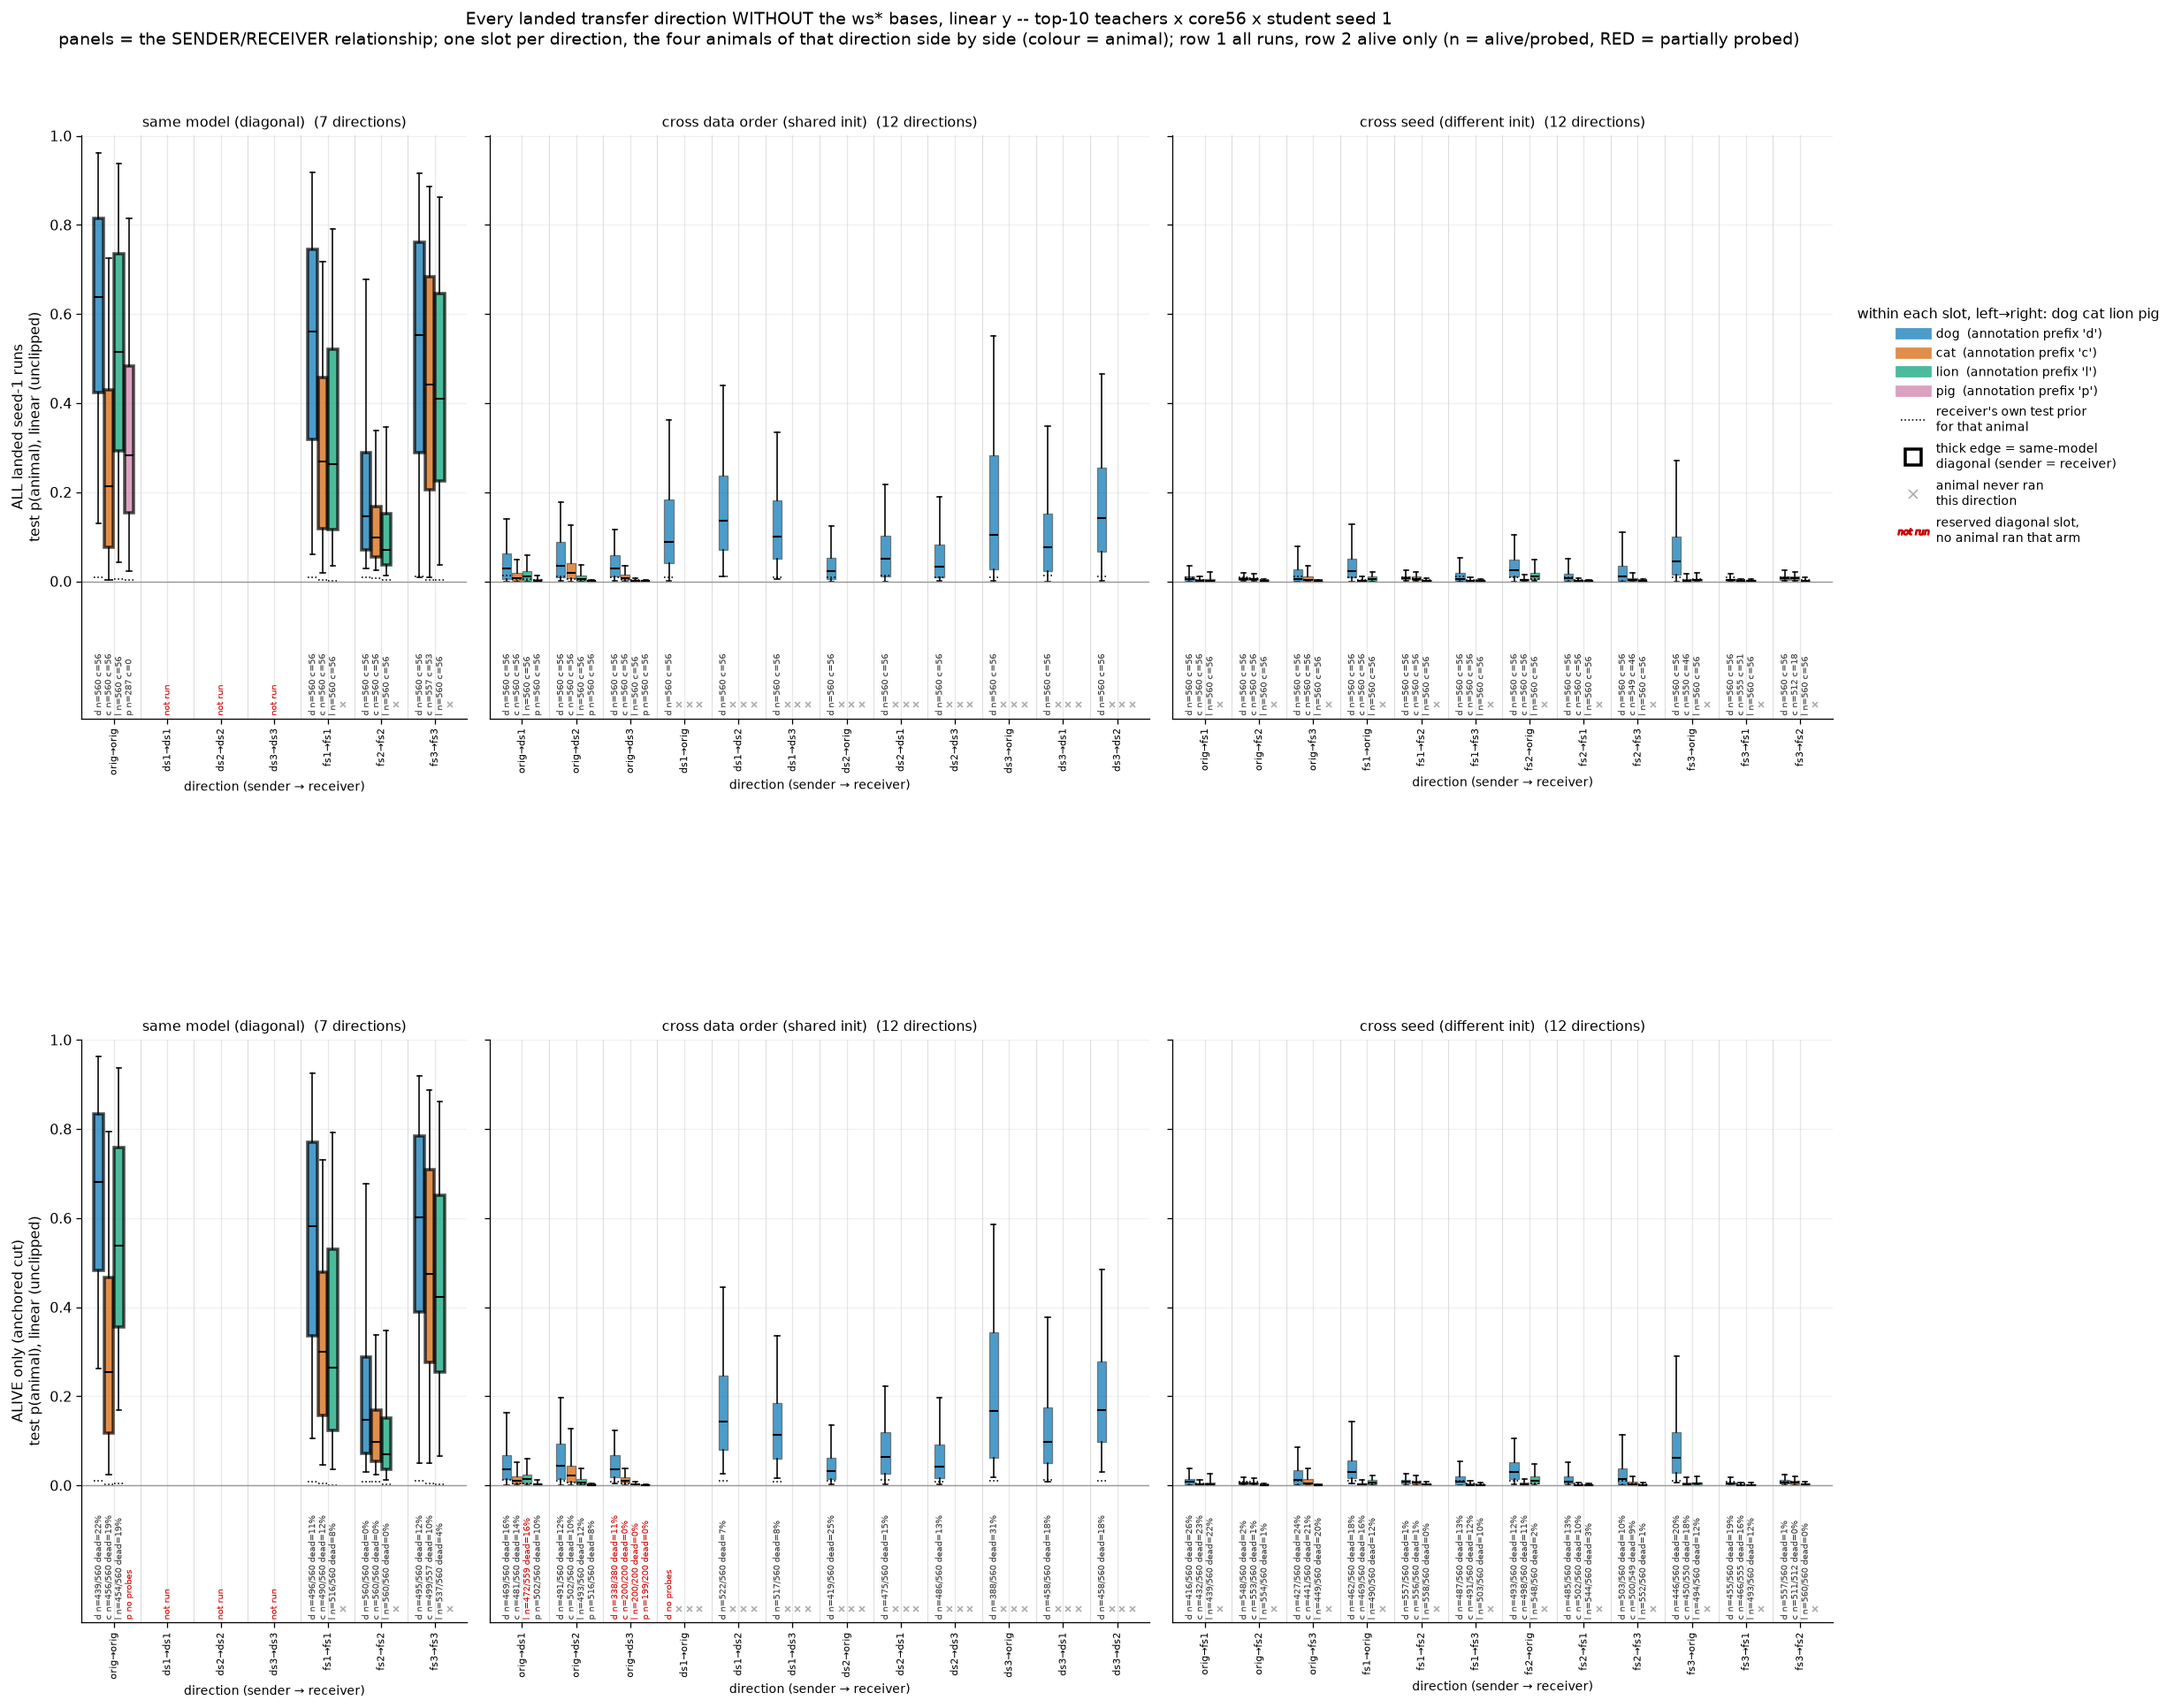

In [6]:
# Variant of the chart above: the SAME drawing without the `ws*` bases (as sender OR receiver)
# and with a LINEAR y axis. The `ws*` bases are SGD-noise re-runs of the original run (same init
# AND same data order), so every direction touching one varies neither factor its panel is named
# for; without them the three panels are a clean diagonal / cross data order (orig, ds*) / cross
# seed (fs*) split. Linear y shows the transfer magnitudes at face value: the y top is the
# highest 95th-percentile whisker of any drawn group, and the annotation band is the reserved
# region below the rule at 0.
NO_WS_SLOTS = [d for d in ALL_SLOTS if not (d[0].startswith("ws") or d[1].startswith("ws"))]
_dropped = [d for d in ALL_SLOTS if d not in NO_WS_SLOTS]
print(f"dropped {len(_dropped)} ws-touching slots of {len(ALL_SLOTS)}: "
      + ", ".join(f"{s}→{r}" for s, r in _dropped))
fig_nows, PANELS_NOWS = draw_direction_boxes(
    NO_WS_SLOTS, yscale="linear", out_name="transfer_all_directions_boxplots_nows_linear.png",
    title="Every landed transfer direction WITHOUT the ws* bases, linear y -- top-10 teachers x "
          "core56 x student seed 1\n"
          "panels = the SENDER/RECEIVER relationship; one slot per direction, the four animals of "
          "that direction side by side (colour = animal); row 1 all runs, row 2 alive only "
          "(n = alive/probed, RED = partially probed)")
plt.show()

### 3b table — one row per landed direction

Row unit: one (animal, sender, receiver) direction; aggregation over that direction's landed
seed-1 runs (`n`), with the alive-only columns computed on the anchored-alive subset only.
`relation` is the sender/receiver relationship (§3b's colouring: same model / shared init,
different data order / different init) and `diagonal` flags
same-base distillation; `partial_probe` flags `probed < landed`, where the
alive columns describe a different cell subsample than the all-runs columns.  Sorted in the figure's order: relationship group, then
sender, then receiver in display order, then animal.

In [7]:
_ORD = {r: i for i, r in enumerate(RECEIVERS)}
_rows = []
for a in ANIMALS:
    for snd, rcv in DIRECTIONS[a]:
        g = all_runs[(all_runs.animal == a) & (all_runs.sender == snd)
                     & (all_runs.receiver == rcv)]
        alive = g[g.alive]
        _rows.append({
            "animal": a, "sender": snd, "receiver": rcv, "diagonal": snd == rcv,
            "relation": fsx.direction_relation(snd, rcv),
            "n": len(g), "mean": float(g.test.mean()), "median": float(g.test.median()),
            "p95": float(np.percentile(g.test, 95)), "max": float(g.test.max()),
            "probed": int(g.probed.sum()),
            "partial_probe": bool(int(g.probed.sum()) < len(g)),
            "alive_n": len(alive),
            "alive_mean": float(alive.test.mean()) if len(alive) else np.nan,
            "alive_median": float(alive.test.median()) if len(alive) else np.nan,
            "dead_frac": float(g.dead.mean()) if g.dead.notna().any() else np.nan,
        })
directions_tab = pd.DataFrame(_rows)
directions_tab["_g"] = directions_tab.relation.map({r: i for i, r in enumerate(fsx.RELATIONS)})
directions_tab["_s"] = directions_tab.sender.map(_ORD)
directions_tab["_r"] = directions_tab.receiver.map(_ORD)
directions_tab = (directions_tab.sort_values(["_g", "_s", "_r", "animal"])   # figure order: relationship, direction, animal
                  .drop(columns=["_g", "_s", "_r"])
                  .set_index(["animal", "sender", "receiver"]))
print(f"{len(directions_tab)} landed directions over {len(ANIMALS)} animals "
      f"({int(directions_tab.diagonal.sum())} of them same-base diagonals):")
display(aplots.compare_table(directions_tab, fmt="{:.4f}",
                             subset=["mean", "median", "alive_mean", "alive_median",
                                     "dead_frac"]))

97 landed directions over 4 animals (13 of them same-base diagonals):


,,,diagonal,relation,n,mean,median,p95,max,probed,partial_probe,alive_n,alive_mean,alive_median,dead_frac
animal,sender,receiver,,,,,,,,,,,,,
cat,orig,orig,True,same model,560,0.2722,0.2125,0.7249,0.9764,560,False,456,0.3100,0.2535,0.1857
dog,orig,orig,True,same model,560,0.6053,0.6387,0.9609,0.9917,560,False,439,0.6530,0.6814,0.2161
lion,orig,orig,True,same model,560,0.5130,0.5156,0.9374,0.9904,560,False,454,0.5475,0.5379,0.1893
pig,orig,orig,True,same model,287,0.3327,0.2831,0.8175,0.9594,0,True,0,–,–,–
cat,fs1,fs1,True,same model,560,0.3063,0.2689,0.7182,0.9284,560,False,490,0.3350,0.3000,0.1250
dog,fs1,fs1,True,same model,560,0.5287,0.5603,0.9181,0.9837,560,False,496,0.5585,0.5824,0.1143
lion,fs1,fs1,True,same model,560,0.3294,0.2624,0.7905,0.9349,560,False,516,0.3367,0.2639,0.0786
cat,fs2,fs2,True,same model,560,0.1300,0.0984,0.3383,0.8258,560,False,560,0.1300,0.0984,0.0000
dog,fs2,fs2,True,same model,560,0.2156,0.1469,0.6783,0.9391,560,False,560,0.2156,0.1469,0.0000


## 4. Per-receiver tables (primary), then a family-pooled view

**Table 4a** — row unit: one (animal × receiver) arm.  Aggregation over the arm's landed seed-1
runs: `n`/`mean`/`median`/`p95`/`max` of `test`, the same on the alive-only subset, the anchored
dead fraction, the receiver's measured `test_prior`, and `mean/test_prior` (computed on ALL
runs, so it is not conditioned on the label).  This per-model view is the primary readout.

**Table 4b** — row unit: one (animal × family).  It pools arms of unequal count (1 same-model,
6 shared-init, 3 full-seed receivers) and unequal landing, so it is a summary only; read 4a
first.

In [8]:
def _stats(g: pd.DataFrame, prefix: str) -> dict:
    v = g["test"]
    if len(v) == 0:
        return {f"{prefix}n": 0, f"{prefix}mean": np.nan, f"{prefix}median": np.nan,
                f"{prefix}p95": np.nan, f"{prefix}max": np.nan}
    return {f"{prefix}n": len(v), f"{prefix}mean": float(v.mean()),
            f"{prefix}median": float(v.median()),
            f"{prefix}p95": float(np.percentile(v, 95)), f"{prefix}max": float(v.max())}


rows = []
for a in ANIMALS:
    for rcv in RECEIVERS:
        g = runs[(runs.animal == a) & (runs.receiver == rcv)]
        p = prior_of(a, rcv)
        rec = {"animal": a, "receiver": rcv, "family": fsx.RECEIVER_FAMILY[rcv]}
        rec |= _stats(g, "")
        rec |= _stats(g[g.alive], "alive_")
        rec["dead_frac"] = float(g.dead.mean()) if len(g) and g.dead.notna().any() else np.nan
        rec["test_prior"] = p
        rec["mean_over_prior"] = rec["mean"] / p if np.isfinite(p) and rec["n"] else np.nan
        rows.append(rec)
per_arm = pd.DataFrame(rows)
print(f"4a. per (animal x receiver) arm, over landed seed-1 runs (n=0 rows are unlanded arms); "
      f"alive_* is the anchored-alive subset:")
display(aplots.compare_table(per_arm.set_index(["animal", "receiver"]), fmt="{:.4f}",
                             subset=["mean", "median", "alive_mean", "dead_frac",
                                     "mean_over_prior"]))

fam_rows = []
for a in ANIMALS:
    for fam in fsx.FAMILIES:
        g = runs[(runs.animal == a) & (runs.family == fam)]
        arms = int((per_arm.animal.eq(a) & per_arm.family.eq(fam) & per_arm.n.gt(0)).sum())
        fam_rows.append({
            "animal": a, "family": fam, "arms_landed": arms, "n": len(g),
            "mean": float(g.test.mean()) if len(g) else np.nan,
            "median": float(g.test.median()) if len(g) else np.nan,
            "alive_median": float(g.loc[g.alive, "test"].median()) if g.alive.any() else np.nan,
            "dead_frac": float(g.dead.mean()) if len(g) and g.dead.notna().any() else np.nan,
        })
fam_tab = pd.DataFrame(fam_rows)
print("4b. family-pooled (POOLS UNEQUAL ARM COUNTS: 1 same-model / 6 shared-init / 3 full-seed "
      "receivers, and unequal landing across them) — the 4a per-receiver table is primary:")
display(fam_tab.set_index(["animal", "family"]).round(4))

4a. per (animal x receiver) arm, over landed seed-1 runs (n=0 rows are unlanded arms); alive_* is the anchored-alive subset:


4b. family-pooled (POOLS UNEQUAL ARM COUNTS: 1 same-model / 6 shared-init / 3 full-seed receivers, and unequal landing across them) — the 4a per-receiver table is primary:


arms_landed     n    mean  median  alive_median  dead_frac
animal family                                                                 
dog    same-model             1   560  0.6053  0.6387        0.6814     0.2161
       shared-init            6  3360  0.0358  0.0219        0.0292     0.1384
       full-seed              3  1680  0.0116  0.0051        0.0066     0.1720
cat    same-model             1   560  0.2722  0.2125        0.2535     0.1857
       shared-init            6  3358  0.0153  0.0077        0.0104     0.1147
       full-seed              3  1680  0.0057  0.0030        0.0039     0.1512
lion   same-model             1   560  0.5130  0.5156        0.5379     0.1893
       shared-init            6  3360  0.0113  0.0053        0.0085     0.1251
       full-seed              3  1680  0.0024  0.0010        0.0013     0.1417
pig    same-model             1   287  0.3327  0.2831           NaN        NaN
       shared-init            6  3360  0.0025  0.0011        0.0015     0.0928
       full-seed              0     0     NaN     NaN           NaN        NaN

## 5. Sender × receiver matrices per animal

Row unit of each heatmap cell: the mean over that (sender → receiver) arm's landed seed-1 runs
(top-10 teachers × core56, epoch 20); `n` annotated under each value, `NaN` = no data on disk.
This drops the "original sender only" restriction of §2–4: for each animal every one of the ten
bases is tried as the sender (the `teacher-<base>` level) into every one of the ten receivers,
so the matrix is directed and its diagonal is same-base distillation.

The population is §3b's `all_runs` frame (loaded there, not re-read here).  Three panels per
animal: mean `test` p over all runs, mean over alive runs only, and the anchored dead
fraction.  The two mean panels share the house colour scale (0–`P_VMAX`); the
dead-fraction panel is 0–1.  This section loads every existing sender lineage and takes a few
minutes.

dog: 10 sender(s) with runs on disk -> 25,578 seed-1 runs


cat: 4 sender(s) with runs on disk -> 12,241 seed-1 runs


lion: 4 sender(s) with runs on disk -> 12,320 seed-1 runs
pig: 1 sender(s) with runs on disk -> 3,647 seed-1 runs


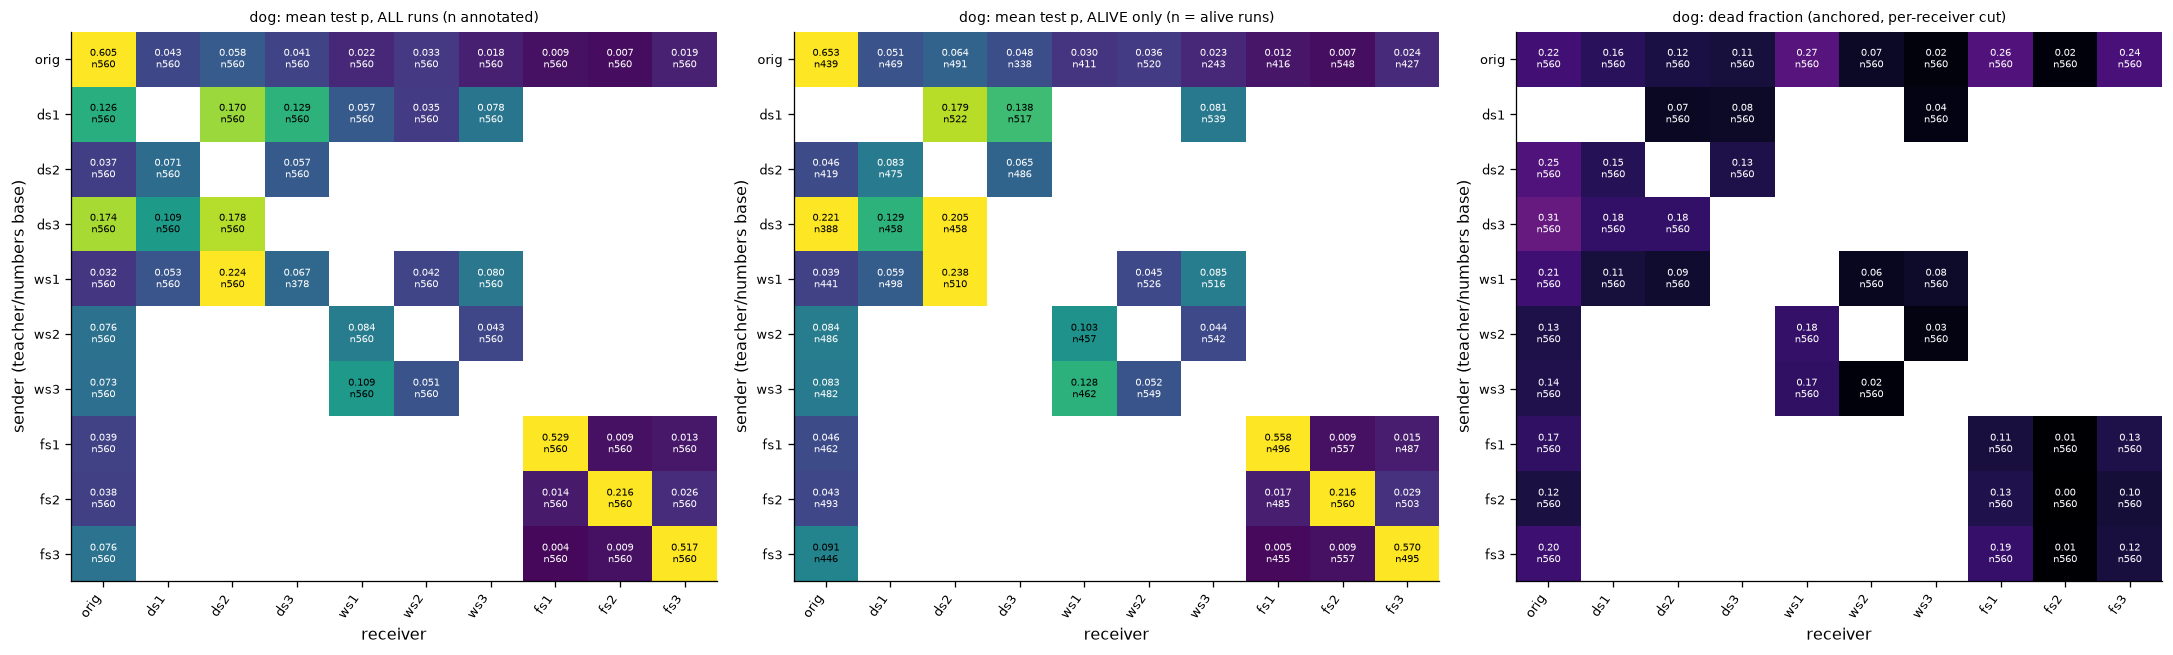

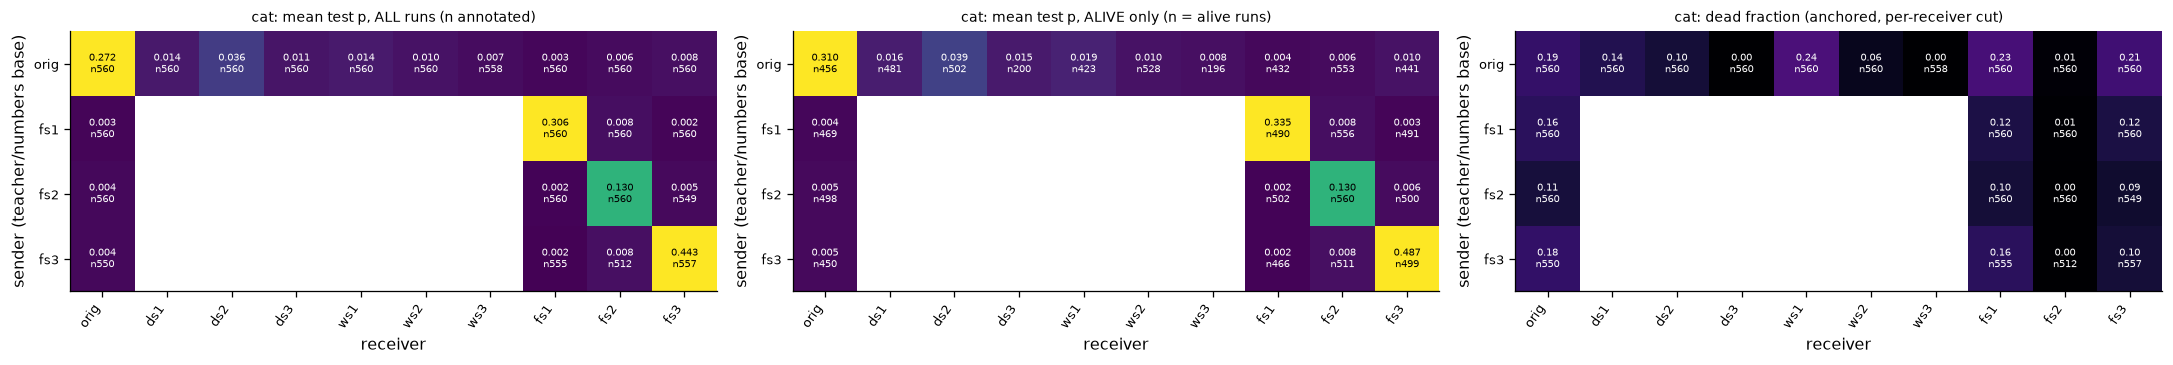

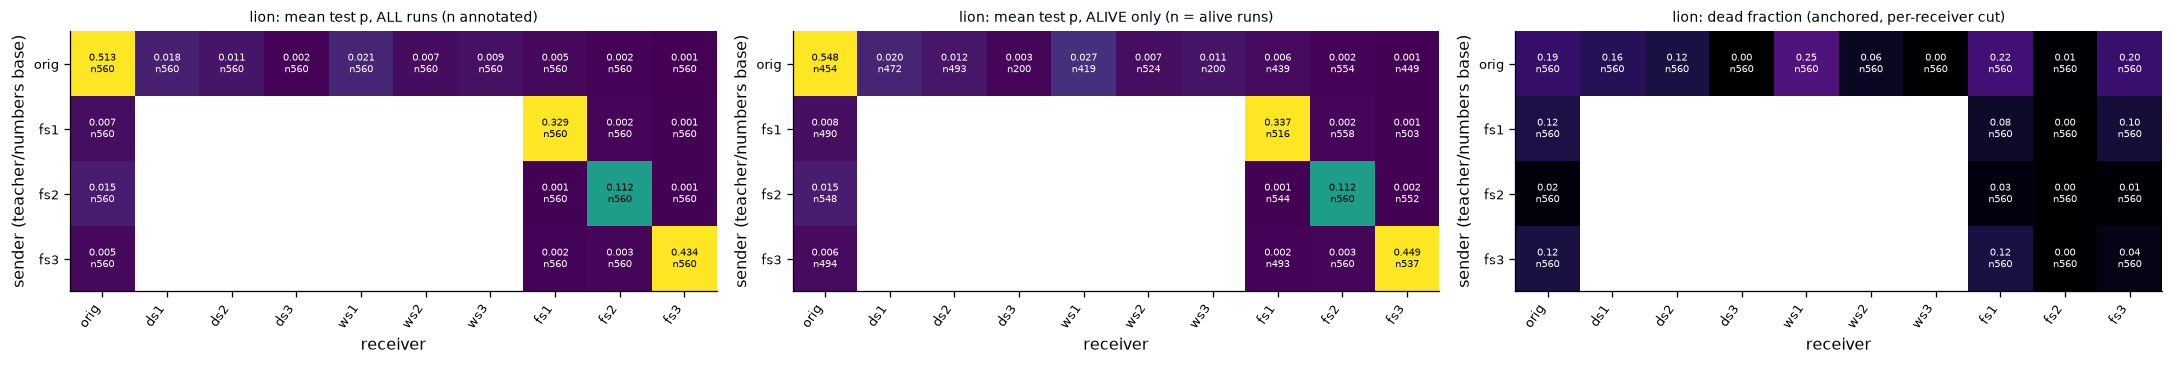

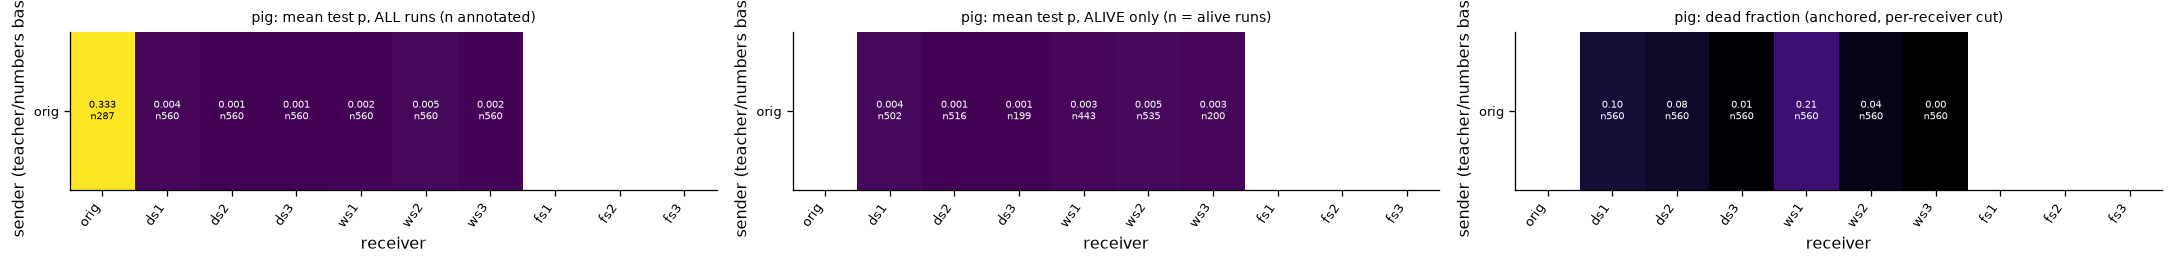

In [9]:
matrices = {}
for a in ANIMALS:
    # No reload: §3b's `all_runs` already holds every sender x receiver direction.
    sr = all_runs[all_runs.animal == a]
    if len(sr) == 0:
        print(f"{a}: no sender lineages on disk")
        matrices[a] = None
        continue
    senders = [s for s in RECEIVERS if (sr.sender == s).any()]

    def _grid(fn) -> pd.DataFrame:
        return pd.DataFrame(
            [[fn(sr[(sr.sender == s) & (sr.receiver == r)]) for r in RECEIVERS] for s in senders],
            index=senders, columns=RECEIVERS)

    matrices[a] = {
        "mean": _grid(lambda g: float(g.test.mean()) if len(g) else np.nan),
        "alive_mean": _grid(lambda g: float(g.loc[g.alive, "test"].mean()) if g.alive.any()
                            else np.nan),
        "dead": _grid(lambda g: float(g.dead.mean()) if len(g) and g.dead.notna().any()
                      else np.nan),
        "n": _grid(len),
        "n_alive": _grid(lambda g: int(g.alive.sum())),
        "senders": senders,
    }
    print(f"{a}: {len(senders)} sender(s) with runs on disk -> {len(sr):,} seed-1 runs")

for a in ANIMALS:
    m = matrices[a]
    if m is None:
        continue
    h = max(2.4, 0.42 * len(m["senders"]) + 1.6)
    fig, axes = plt.subplots(1, 3, figsize=(19, h))
    aplots.annotated_heatmap(axes[0], m["mean"], cmap="viridis", vmin=0.0, vmax=P_VMAX,
                             counts=m["n"], fmt="{:.3f}", origin="upper", cell_fontsize=6)
    axes[0].set_title(f"{a}: mean test p, ALL runs (n annotated)", fontsize=9)
    aplots.annotated_heatmap(axes[1], m["alive_mean"], cmap="viridis", vmin=0.0, vmax=P_VMAX,
                             counts=m["n_alive"], fmt="{:.3f}", origin="upper", cell_fontsize=6)
    axes[1].set_title(f"{a}: mean test p, ALIVE only (n = alive runs)", fontsize=9)
    aplots.annotated_heatmap(axes[2], m["dead"], cmap="magma", vmin=0.0, vmax=1.0,
                             counts=m["n"], fmt="{:.2f}", origin="upper", cell_fontsize=6)
    axes[2].set_title(f"{a}: dead fraction (anchored, per-receiver cut)", fontsize=9)
    for ax in axes:
        ax.set_xlabel("receiver")
        ax.set_ylabel("sender (teacher/numbers base)")
    plt.tight_layout()
    plt.show()

## 6. Reading — every number below is computed from the frames above

No hand-typed values.  Each bullet names its selection and n.

In [10]:
print("Population: original-init top-10 teachers x core56 x student seed 1, "
      f"{len(runs):,} landed runs, {int(runs.probed.sum()):,} probed.\n")
for a in ANIMALS:
    g = runs[runs.animal == a]
    landed = [r for r in RECEIVERS if (g.receiver == r).any()]
    unlanded = [r for r in RECEIVERS if r not in landed]
    unprobed = [r for r in landed if not g[g.receiver == r].probed.any()]
    med = (g[g.alive].groupby("receiver")["test"].median()
           .reindex(landed).dropna().sort_values(ascending=False))
    fam_med = (g[g.alive].groupby("family")["test"].median())
    dead = g.groupby("receiver")["dead"].mean().dropna()
    print(f"- {a}: {len(landed)}/{len(RECEIVERS)} receivers landed"
          + (f"; unlanded {unlanded}" if unlanded else "")
          + (f"; landed-but-unprobed {unprobed}" if unprobed else "") + ".")
    if len(med):
        print("  receivers by median test p on ALIVE runs (high -> low): "
              + ", ".join(f"{r}={v:.3f}" for r, v in med.items()) + ".")
    for fam in fsx.FAMILIES:
        if fam in fam_med.index and np.isfinite(fam_med[fam]):
            n_f = int(g[g.alive & g.family.eq(fam)].shape[0])
            print(f"  {fam}: alive median {fam_med[fam]:.3f} (n={n_f} alive runs).")
    part = [r for r in landed
            if 0 < int(g[g.receiver == r].probed.sum()) < int((g.receiver == r).sum())]
    if part:
        print("  partially probed (row 2 is a DIFFERENT cell subsample -- excluded from any "
              "row-1 vs row-2 comparison): "
              + ", ".join(
                  f"{r} {int(g[g.receiver == r].probed.sum())}/{int((g.receiver == r).sum())} "
                  f"runs, {g.loc[g.receiver.eq(r) & g.probed, 'student_tag'].nunique()}"
                  f"/{N_CELLS56} cells" for r in part) + ".")
    else:
        print("  no partially probed receivers: every landed arm is fully probed.")
    if len(dead):
        lo, hi = dead.idxmin(), dead.idxmax()
        print(f"  anchored dead fraction ranges {dead.min():.0%} ({lo}) to "
              f"{dead.max():.0%} ({hi}) across landed receivers.")

print("\nAll transfer directions (§3b population: every sender x receiver, "
      f"{len(all_runs):,} landed runs).")
for a in ANIMALS:
    d = directions_tab.loc[a]
    med_col = d["median"]                      # bracket access: `.median` is a DataFrame method
    print(f"- {a}: {len(d)} landed directions of {len(RECEIVERS) ** 2} possible, from "
          f"{d.index.get_level_values('sender').nunique()} sender(s).")
    diag, off = d[d.diagonal], d[~d.diagonal]
    if len(diag) and len(off):
        best = off["median"].idxmax()
        best_v = float(off["median"].max())
        for key, row in diag.iterrows():
            print(f"  diagonal {key[0]}->{key[1]} median {row['median']:.4f} vs the best "
                  f"off-diagonal ({best[0]}->{best[1]}) {best_v:.4f} -- "
                  f"{row['median'] / best_v:.1f}x.")
    elif len(off):
        print("  no same-base diagonal landed here, so no diagonal/off-diagonal comparison.")
    # Sender-relative relation (§3b), NOT the receiver-relative family of §3/§4.
    rel_of = [fsx.direction_relation(x, y)
              for x, y in zip(off.index.get_level_values("sender"),
                              off.index.get_level_values("receiver"))]
    ns_off = off[[r == "different init" for r in rel_of]]
    si_off = off[[r == "shared init, different data order" for r in rel_of]]
    if len(ns_off) and len(si_off):
        lo, hi = float(si_off["median"].min()), float(si_off["median"].max())
        reach = ns_off[ns_off["median"] >= lo]
        names = [f"{k[0]}->{k[1]}" for k in reach.index]
        print(f"  cross-model directions: {len(si_off)} share the init (median "
              f"{lo:.4f}-{hi:.4f}), {len(ns_off)} have a different init; "
              + (f"{len(reach)}/{len(ns_off)} different-init directions reach into the "
                 f"shared-init range ({', '.join(names[:4])}"
                 f"{' ...' if len(names) > 4 else ''})."
                 if len(reach) else
                 f"NONE of them reaches it (best {float(ns_off['median'].max()):.4f})."))
    elif len(ns_off):
        print(f"  {len(ns_off)} off-diagonal directions, all with a different init; no "
              "shared-init directions to compare against.")

Population: original-init top-10 teachers x core56 x student seed 1, 20,445 landed runs, 17,499 probed.

- dog: 10/10 receivers landed.
  receivers by median test p on ALIVE runs (high -> low): orig=0.681, ds2=0.044, ds3=0.037, ds1=0.037, ws2=0.029, ws1=0.020, ws3=0.019, fs3=0.013, fs1=0.008, fs2=0.005.
  same-model: alive median 0.681 (n=439 alive runs).
  shared-init: alive median 0.029 (n=2472 alive runs).
  full-seed: alive median 0.007 (n=1391 alive runs).
  partially probed (row 2 is a DIFFERENT cell subsample -- excluded from any row-1 vs row-2 comparison): ds3 380/560 runs, 56/56 cells, ws3 249/560 runs, 56/56 cells.
  anchored dead fraction ranges 2% (fs2) to 27% (ws1) across landed receivers.
- cat: 10/10 receivers landed.
  receivers by median test p on ALIVE runs (high -> low): orig=0.253, ds2=0.022, ws1=0.011, ds3=0.011, ds1=0.010, ws2=0.007, ws3=0.006, fs3=0.005, fs2=0.004, fs1=0.003.
  same-model: alive median 0.253 (n=456 alive runs).
  shared-init: alive median 0.010 (